# Phase 1 EDA -- AI-Based Disaster Preparedness Assistant
## Cyclone Preparedness Assessment: Karnataka Coastal Districts
### Dakshina Kannada | Udupi | Uttara Kannada

---

**Project**: MLOps -- Cyclone Preparedness Index  
**Data Unit**: Census 2011 Village (N = 1,879)  
**Sources**: SHRUG 2.1 Polygons · Census DCHB · HMIS Health Centres · KSNDMC Rain Gauges · NCRMP-II Shelters · CVI Study (Naik & Kunte, 2023)


## 0. Setup & Data Load

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe
from scipy import stats
from scipy.stats import skew, kurtosis, shapiro

# --- Plot style ----------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": "#0f1117",
    "axes.facecolor": "#1a1d27",
    "axes.edgecolor": "#3a3d4f",
    "axes.labelcolor": "#e0e0e0",
    "text.color": "#e0e0e0",
    "xtick.color": "#b0b0b0",
    "ytick.color": "#b0b0b0",
    "grid.color": "#2a2d3a",
    "grid.linewidth": 0.5,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.facecolor": "#1a1d27",
    "legend.edgecolor": "#3a3d4f",
    "legend.labelcolor": "#e0e0e0",
    "font.family": "DejaVu Sans",
})

PALETTE_DISTRICT = {"Uttara Kannada": "#4FC3F7", "Udupi": "#81C784", "Dakshina Kannada": "#FFB74D"}
TIER_COLORS      = {"Low": "#EF5350", "Medium": "#FFA726", "High": "#66BB6A"}

# --- Data ----------------------------------------------------------------
df = pd.read_parquet("../data/processed/master_village_preparedness.parquet")

# Ensure categorical types
df["preparedness_tier"] = pd.Categorical(df["preparedness_tier"], categories=["Low","Medium","High"], ordered=True)
df["district_name"]     = df["district_name"].astype(str).str.strip()
df["vulnerability_tier"]= df["vulnerability_tier"].astype(str).str.strip()

print(f"Dataset: {df.shape[0]:,} villages × {df.shape[1]} features")
print(f"Districts: {df['district_name'].value_counts().to_dict()}")
print(f"Tauktae-affected: {df['tauktae_affected'].sum():,} villages ({df['tauktae_affected'].mean():.1%})")


Dataset: 1,879 villages × 49 features
Districts: {'Uttara Kannada': 1257, 'Dakshina Kannada': 369, 'Udupi': 253}
Tauktae-affected: 194 villages (10.3%)


## 1. Dataset Overview

In [2]:
# Feature groups
FEATURE_GROUPS = {
    "Identifiers & Spatial": ["area_id","village_code","village_name","district_name","subdistrict_name","lon","lat"],
    "Demographics":          ["population","households","pop_density_sqkm","avg_household_size","sc_share","st_share","vulnerable_pop_share"],
    "Geography & Hazard":    ["elevation_mean","dist_coast_km","cvi_physical","cvi_social","cvi_integrated","vulnerability_tier"],
    "Shelters":              ["dist_nearest_shelter_km","n_shelters_10km","shelter_capacity_nearby","shelter_capacity_per_capita","shelter_road_access"],
    "Healthcare":            ["dist_nearest_hc_km","dist_nearest_phc_km","dist_nearest_hospital_km","n_hc_10km","n_phc_chc_10km","has_phc_or_chc"],
    "Early Warning":         ["dist_nearest_gauge_km","n_gauges_20km"],
    "Infrastructure":        ["road_connectivity_score","drinking_water_score","has_pucca_road","has_major_district_road","bus_connectivity"],
    "Targets":               ["preparedness_score","preparedness_tier","tauktae_affected"],
}

print("╔══════════════════════════════════════════════╗")
print("║         FEATURE GROUP INVENTORY              ║")
print("╚══════════════════════════════════════════════╝")
for grp, cols in FEATURE_GROUPS.items():
    print(f"  {grp:30s}: {len(cols)} features")

print(f"\nTotal rows: {len(df):,}  |  Total features: {df.shape[1]}")
print(f"Missing values: {df.isnull().sum().sum()} (0 -- fully complete dataset)")


╔══════════════════════════════════════════════╗
║         FEATURE GROUP INVENTORY              ║
╚══════════════════════════════════════════════╝
  Identifiers & Spatial         : 7 features
  Demographics                  : 7 features
  Geography & Hazard            : 6 features
  Shelters                      : 5 features
  Healthcare                    : 6 features
  Early Warning                 : 2 features
  Infrastructure                : 5 features
  Targets                       : 3 features

Total rows: 1,879  |  Total features: 49
Missing values: 0 (0 -- fully complete dataset)


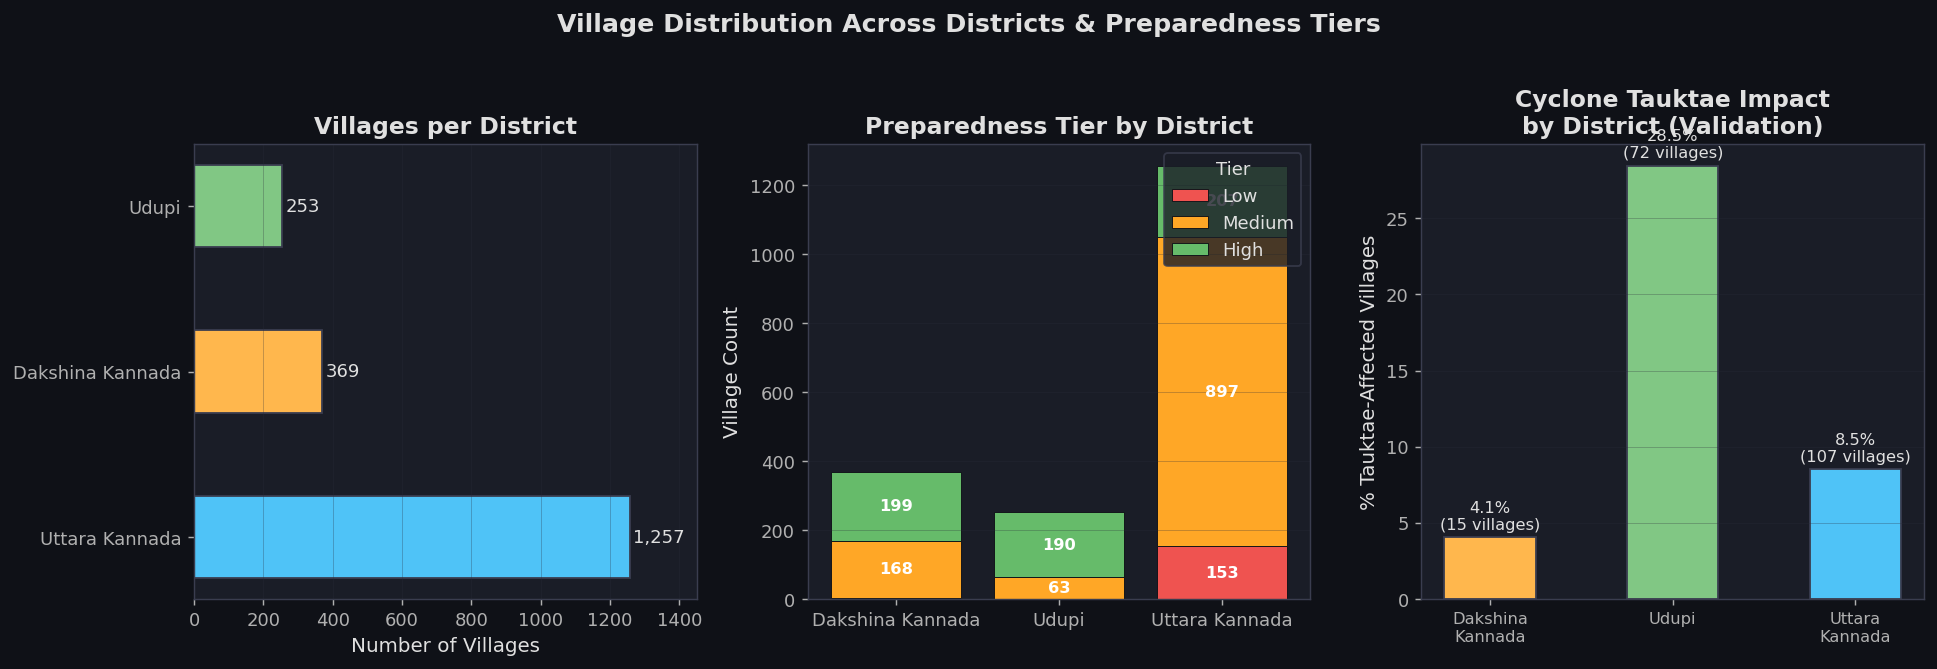

Saved: fig_01_overview.png


In [3]:
# Distribution of villages by district & tier
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Village Distribution Across Districts & Preparedness Tiers", fontsize=14, fontweight="bold", y=1.02)

# Panel 1: Village count by district
dist_counts = df["district_name"].value_counts()
colors_dist  = [PALETTE_DISTRICT[d] for d in dist_counts.index]
bars = axes[0].barh(dist_counts.index, dist_counts.values, color=colors_dist, edgecolor="#3a3d4f", height=0.5)
for bar, val in zip(bars, dist_counts.values):
    axes[0].text(bar.get_width() + 10, bar.get_y() + bar.get_height()/2,
                 f"{val:,}", va="center", fontsize=10, color="#e0e0e0")
axes[0].set_xlabel("Number of Villages")
axes[0].set_title("Villages per District", fontweight="bold")
axes[0].set_xlim(0, 1450)
axes[0].grid(axis="x", alpha=0.3)

# Panel 2: Preparedness tier by district (stacked)
tier_dist = df.groupby(["district_name","preparedness_tier"]).size().unstack(fill_value=0)
tier_dist = tier_dist[["Low","Medium","High"]]
bottom = np.zeros(len(tier_dist))
for tier, col in zip(["Low","Medium","High"], [TIER_COLORS["Low"],TIER_COLORS["Medium"],TIER_COLORS["High"]]):
    if tier in tier_dist.columns:
        vals = tier_dist[tier].values
        axes[1].bar(tier_dist.index, vals, bottom=bottom, color=col, label=tier, edgecolor="#0f1117", linewidth=0.5)
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v > 20:
                axes[1].text(i, b + v/2, str(v), ha="center", va="center", fontsize=9, color="white", fontweight="bold")
        bottom += vals
axes[1].set_title("Preparedness Tier by District", fontweight="bold")
axes[1].set_ylabel("Village Count")
axes[1].legend(title="Tier", loc="upper right")
axes[1].grid(axis="y", alpha=0.3)

# Panel 3: Tauktae affected breakdown
tauktae_dist = df.groupby("district_name")["tauktae_affected"].agg(["sum","count"])
tauktae_dist["pct"] = tauktae_dist["sum"] / tauktae_dist["count"] * 100
x_pos = np.arange(len(tauktae_dist))
colors3 = [PALETTE_DISTRICT[d] for d in tauktae_dist.index]
axes[2].bar(x_pos, tauktae_dist["pct"], color=colors3, edgecolor="#3a3d4f", width=0.5)
for i, (row_idx, row) in enumerate(tauktae_dist.iterrows()):
    axes[2].text(i, row["pct"] + 0.5, f"{row['pct']:.1f}%\n({int(row['sum'])} villages)",
                 ha="center", fontsize=9, color="#e0e0e0")
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels([d.replace(" ", "\n") for d in tauktae_dist.index], fontsize=9)
axes[2].set_ylabel("% Tauktae-Affected Villages")
axes[2].set_title("Cyclone Tauktae Impact\nby District (Validation)", fontweight="bold")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_01_overview.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()
print("Saved: fig_01_overview.png")


## 2. Univariate Feature Distributions

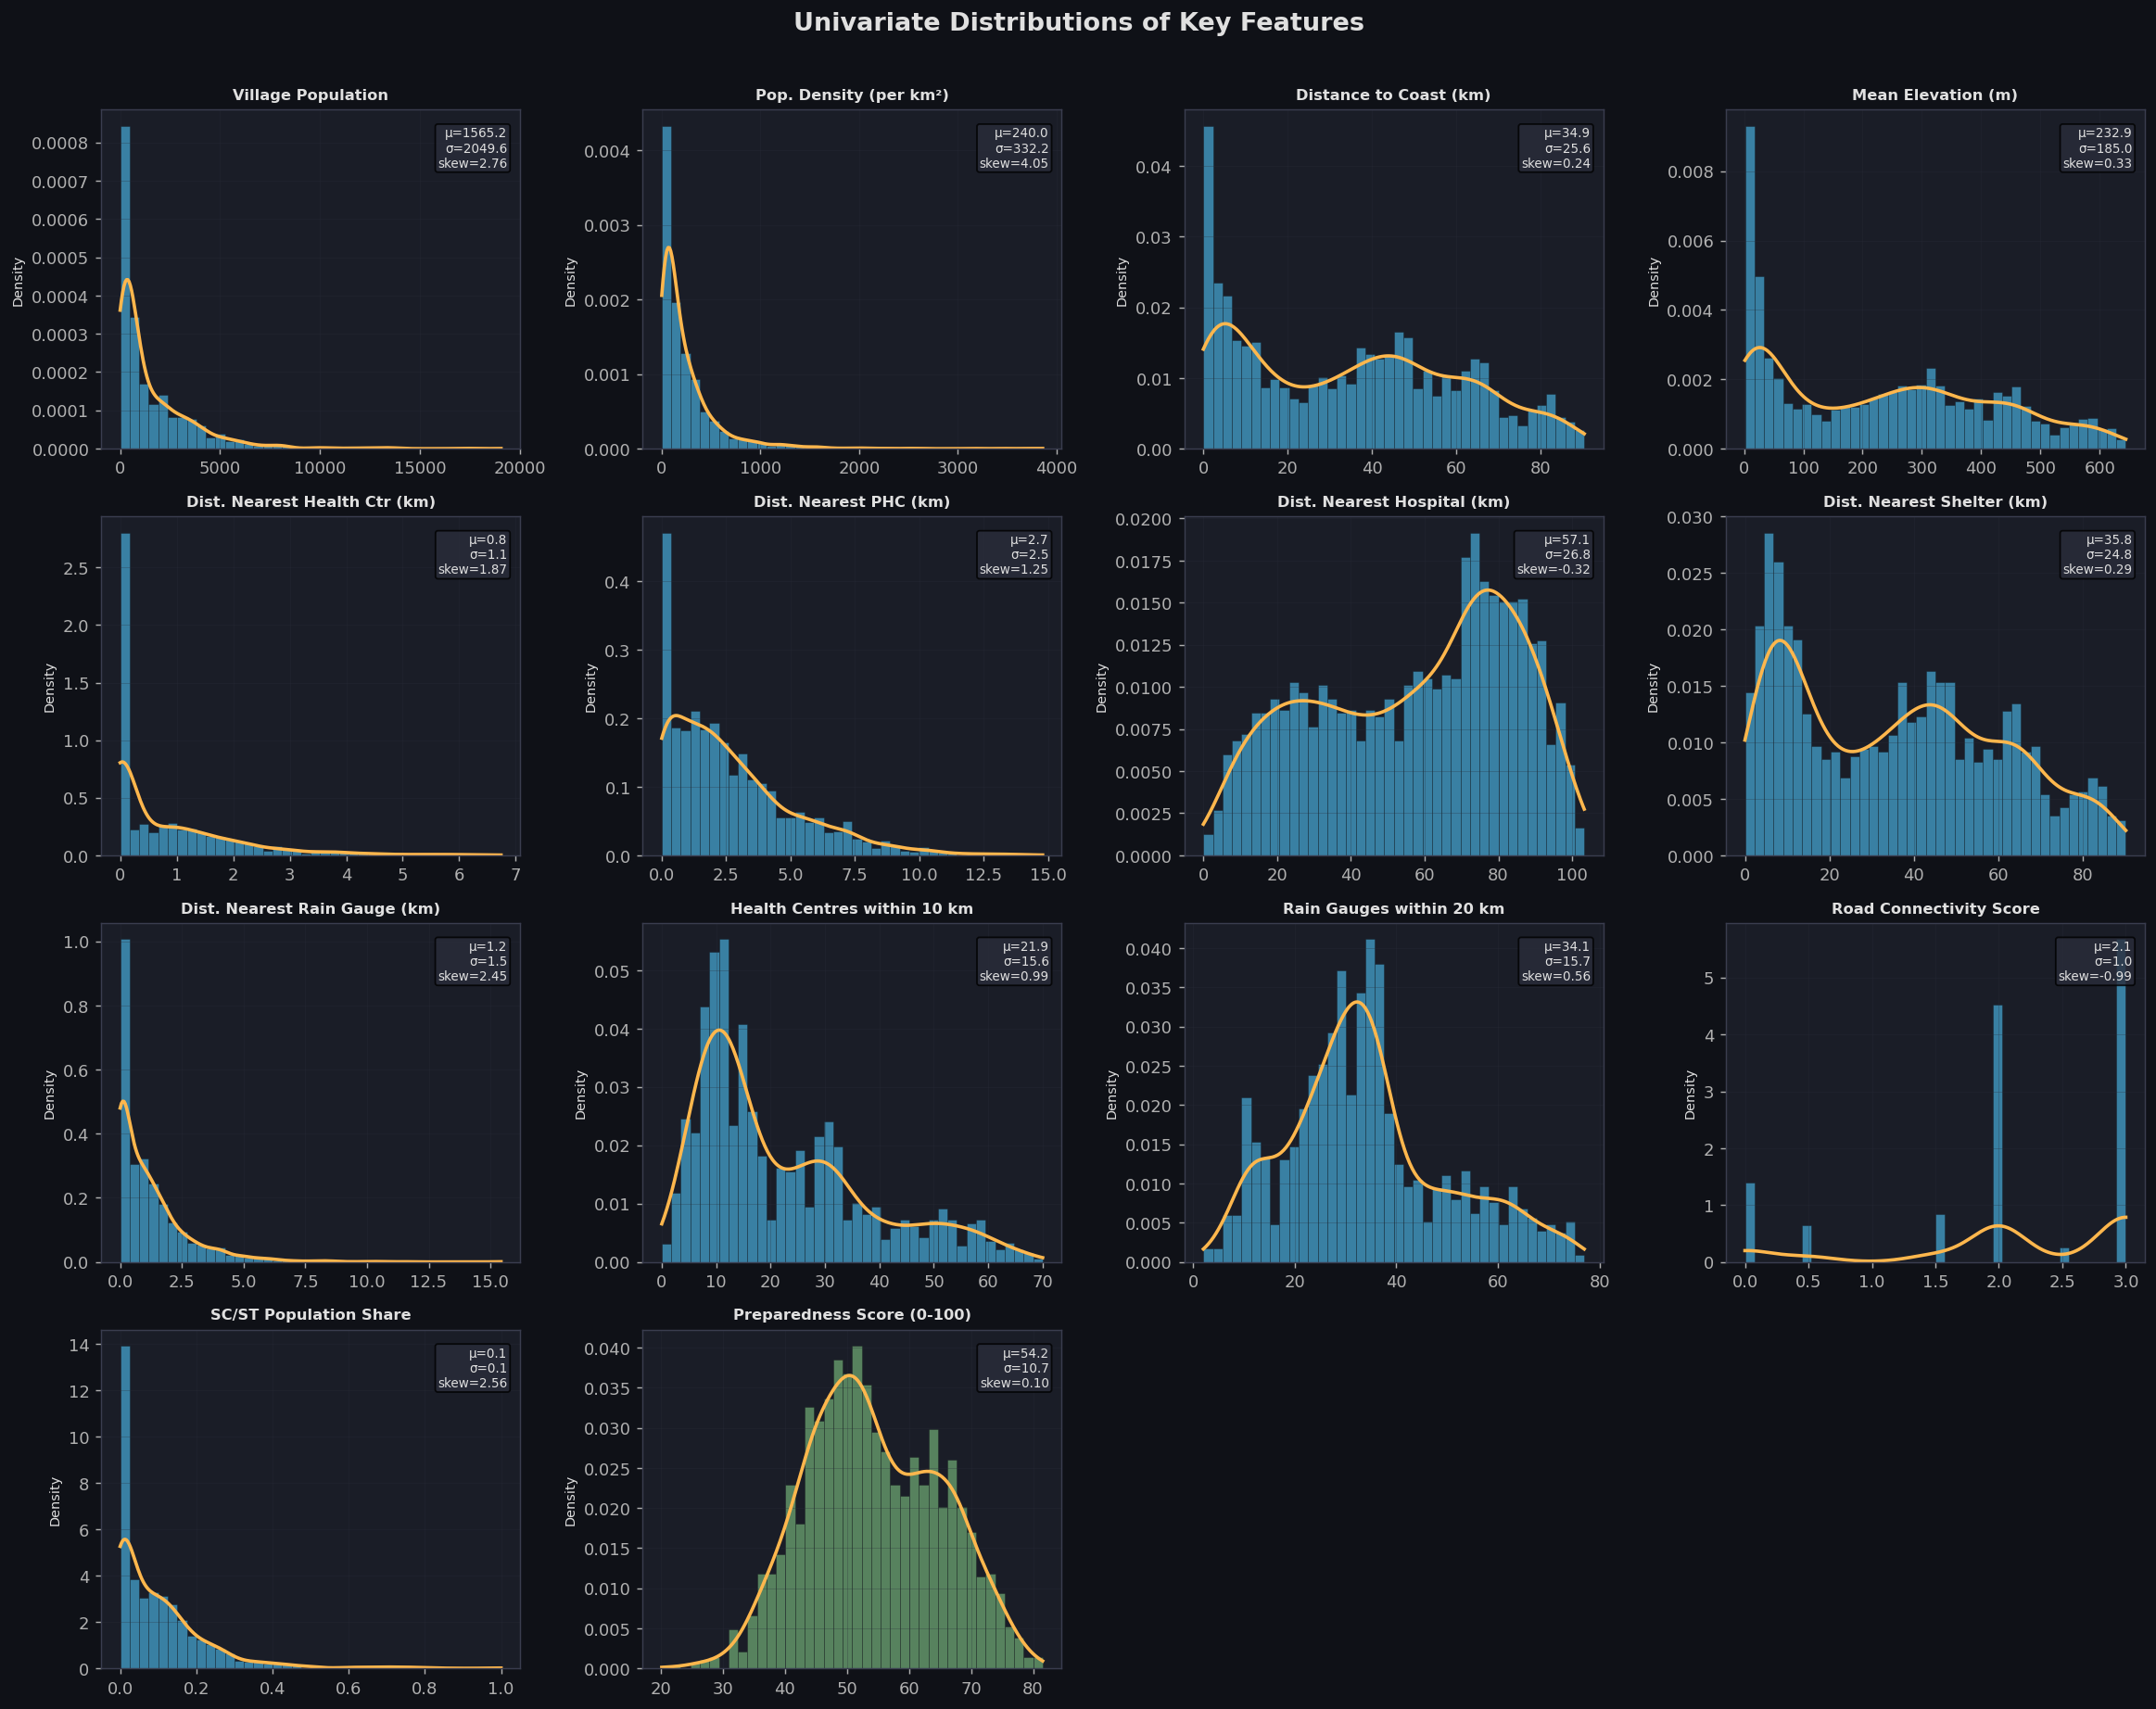

Key Skewness Summary:
  population                              : skew = +2.76  ⚠ HIGH SKEW
  pop_density_sqkm                        : skew = +4.05  ⚠ HIGH SKEW
  dist_coast_km                           : skew = +0.24  
  elevation_mean                          : skew = +0.33  
  dist_nearest_hc_km                      : skew = +1.87  ⚠ HIGH SKEW
  dist_nearest_phc_km                     : skew = +1.25  
  dist_nearest_hospital_km                : skew = -0.32  
  dist_nearest_shelter_km                 : skew = +0.29  
  dist_nearest_gauge_km                   : skew = +2.45  ⚠ HIGH SKEW
  n_hc_10km                               : skew = +0.99  
  n_gauges_20km                           : skew = +0.56  
  road_connectivity_score                 : skew = -0.99  
  vulnerable_pop_share                    : skew = +2.56  ⚠ HIGH SKEW
  preparedness_score                      : skew = +0.10  


In [4]:
NUMERIC_FEATURES = [
    "population", "pop_density_sqkm", "dist_coast_km", "elevation_mean",
    "dist_nearest_hc_km", "dist_nearest_phc_km", "dist_nearest_hospital_km",
    "dist_nearest_shelter_km", "dist_nearest_gauge_km",
    "n_hc_10km", "n_gauges_20km", "road_connectivity_score",
    "vulnerable_pop_share", "preparedness_score"
]

FEATURE_LABELS = {
    "population": "Village Population",
    "pop_density_sqkm": "Pop. Density (per km²)",
    "dist_coast_km": "Distance to Coast (km)",
    "elevation_mean": "Mean Elevation (m)",
    "dist_nearest_hc_km": "Dist. Nearest Health Ctr (km)",
    "dist_nearest_phc_km": "Dist. Nearest PHC (km)",
    "dist_nearest_hospital_km": "Dist. Nearest Hospital (km)",
    "dist_nearest_shelter_km": "Dist. Nearest Shelter (km)",
    "dist_nearest_gauge_km": "Dist. Nearest Rain Gauge (km)",
    "n_hc_10km": "Health Centres within 10 km",
    "n_gauges_20km": "Rain Gauges within 20 km",
    "road_connectivity_score": "Road Connectivity Score",
    "vulnerable_pop_share": "SC/ST Population Share",
    "preparedness_score": "Preparedness Score (0-100)",
}

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()
fig.suptitle("Univariate Distributions of Key Features", fontsize=15, fontweight="bold", y=1.01)

for i, feat in enumerate(NUMERIC_FEATURES):
    ax = axes[i]
    data = df[feat].dropna()
    
    # Histogram with KDE
    color = "#4FC3F7" if feat != "preparedness_score" else "#81C784"
    ax.hist(data, bins=40, color=color, alpha=0.6, edgecolor="#0f1117", density=True, linewidth=0.3)
    
    # KDE overlay
    from scipy.stats import gaussian_kde
    kde = gaussian_kde(data[data.notna()], bw_method="scott")
    x_range = np.linspace(data.min(), data.max(), 300)
    ax.plot(x_range, kde(x_range), color="#FFB74D", linewidth=2)
    
    # Stats annotation
    sk = skew(data)
    kt = kurtosis(data)
    ax.text(0.97, 0.95, f"μ={data.mean():.1f}\nσ={data.std():.1f}\nskew={sk:.2f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=7.5,
            color="#e0e0e0", bbox=dict(boxstyle="round,pad=0.2", facecolor="#2a2d3a", alpha=0.8))
    
    ax.set_title(FEATURE_LABELS.get(feat, feat), fontsize=9, fontweight="bold")
    ax.set_xlabel("", fontsize=8)
    ax.set_ylabel("Density", fontsize=8)
    ax.grid(alpha=0.3)

# Hide unused axes
for j in range(len(NUMERIC_FEATURES), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("../notebooks/fig_02_distributions.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()
print("Key Skewness Summary:")
for f in NUMERIC_FEATURES:
    s = skew(df[f].dropna())
    flag = "⚠ HIGH SKEW" if abs(s) > 1.5 else ""
    print(f"  {f:40s}: skew = {s:+.2f}  {flag}")


## 3. Correlation Heatmaps

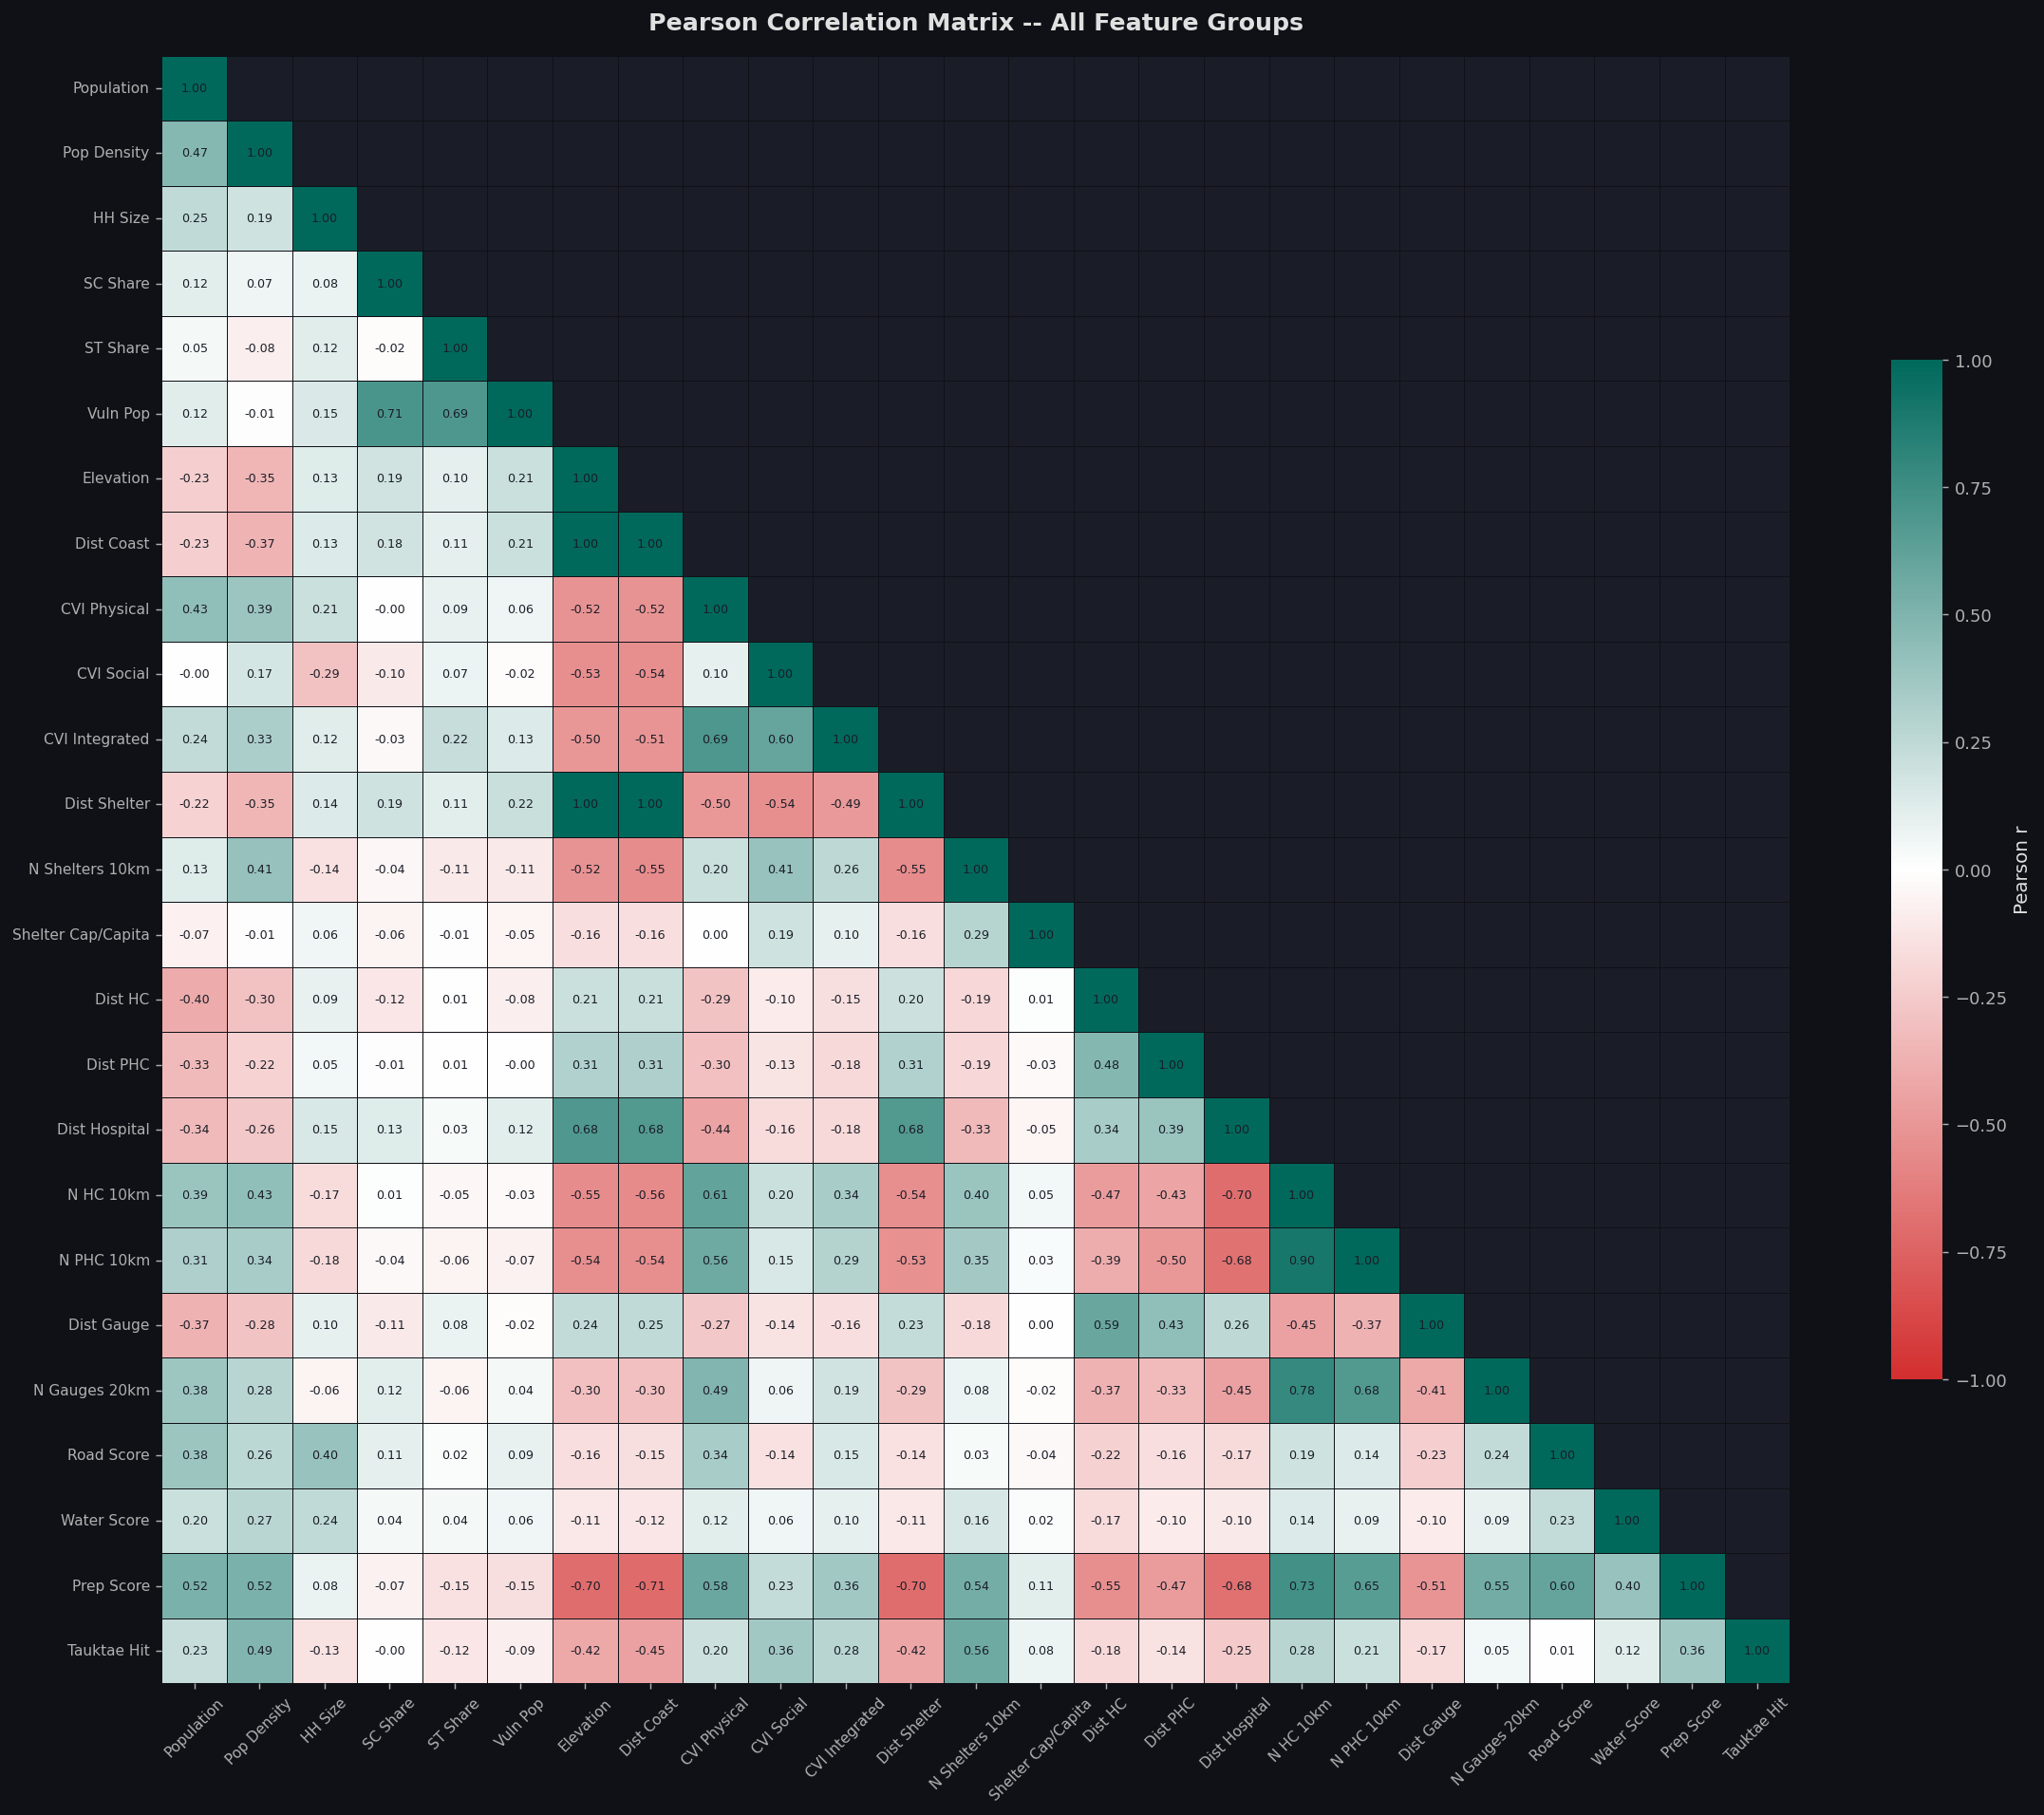

In [5]:
# Full correlation matrix (Pearson) of numeric features
numeric_df = df[[
    "population", "pop_density_sqkm", "avg_household_size",
    "sc_share", "st_share", "vulnerable_pop_share",
    "elevation_mean", "dist_coast_km",
    "cvi_physical", "cvi_social", "cvi_integrated",
    "dist_nearest_shelter_km", "n_shelters_10km", "shelter_capacity_per_capita",
    "dist_nearest_hc_km", "dist_nearest_phc_km", "dist_nearest_hospital_km",
    "n_hc_10km", "n_phc_chc_10km",
    "dist_nearest_gauge_km", "n_gauges_20km",
    "road_connectivity_score", "drinking_water_score",
    "preparedness_score", "tauktae_affected"
]].copy()

corr_matrix = numeric_df.corr(method="pearson")

short_labels = {
    "population": "Population",
    "pop_density_sqkm": "Pop Density",
    "avg_household_size": "HH Size",
    "sc_share": "SC Share",
    "st_share": "ST Share",
    "vulnerable_pop_share": "Vuln Pop",
    "elevation_mean": "Elevation",
    "dist_coast_km": "Dist Coast",
    "cvi_physical": "CVI Physical",
    "cvi_social": "CVI Social",
    "cvi_integrated": "CVI Integrated",
    "dist_nearest_shelter_km": "Dist Shelter",
    "n_shelters_10km": "N Shelters 10km",
    "shelter_capacity_per_capita": "Shelter Cap/Capita",
    "dist_nearest_hc_km": "Dist HC",
    "dist_nearest_phc_km": "Dist PHC",
    "dist_nearest_hospital_km": "Dist Hospital",
    "n_hc_10km": "N HC 10km",
    "n_phc_chc_10km": "N PHC 10km",
    "dist_nearest_gauge_km": "Dist Gauge",
    "n_gauges_20km": "N Gauges 20km",
    "road_connectivity_score": "Road Score",
    "drinking_water_score": "Water Score",
    "preparedness_score": "Prep Score",
    "tauktae_affected": "Tauktae Hit",
}

corr_matrix.index   = [short_labels.get(c, c) for c in corr_matrix.index]
corr_matrix.columns = [short_labels.get(c, c) for c in corr_matrix.columns]

# Build custom colormap (dark red → white → dark teal)
cmap_custom = LinearSegmentedColormap.from_list(
    "rw_teal", ["#D32F2F", "#FFFFFF", "#00695C"], N=256
)

fig, ax = plt.subplots(figsize=(18, 15))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix, mask=mask, ax=ax,
    cmap=cmap_custom, center=0, vmin=-1, vmax=1,
    linewidths=0.3, linecolor="#0f1117",
    annot=True, fmt=".2f", annot_kws={"size": 7, "color": "#1a1d27"},
    square=True,
    cbar_kws={"shrink": 0.6, "label": "Pearson r"}
)
ax.set_title("Pearson Correlation Matrix -- All Feature Groups", fontsize=14, fontweight="bold", pad=15)
ax.tick_params(axis="x", rotation=45, labelsize=8.5)
ax.tick_params(axis="y", rotation=0,  labelsize=8.5)

plt.tight_layout()
plt.savefig("../notebooks/fig_03_correlation_full.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


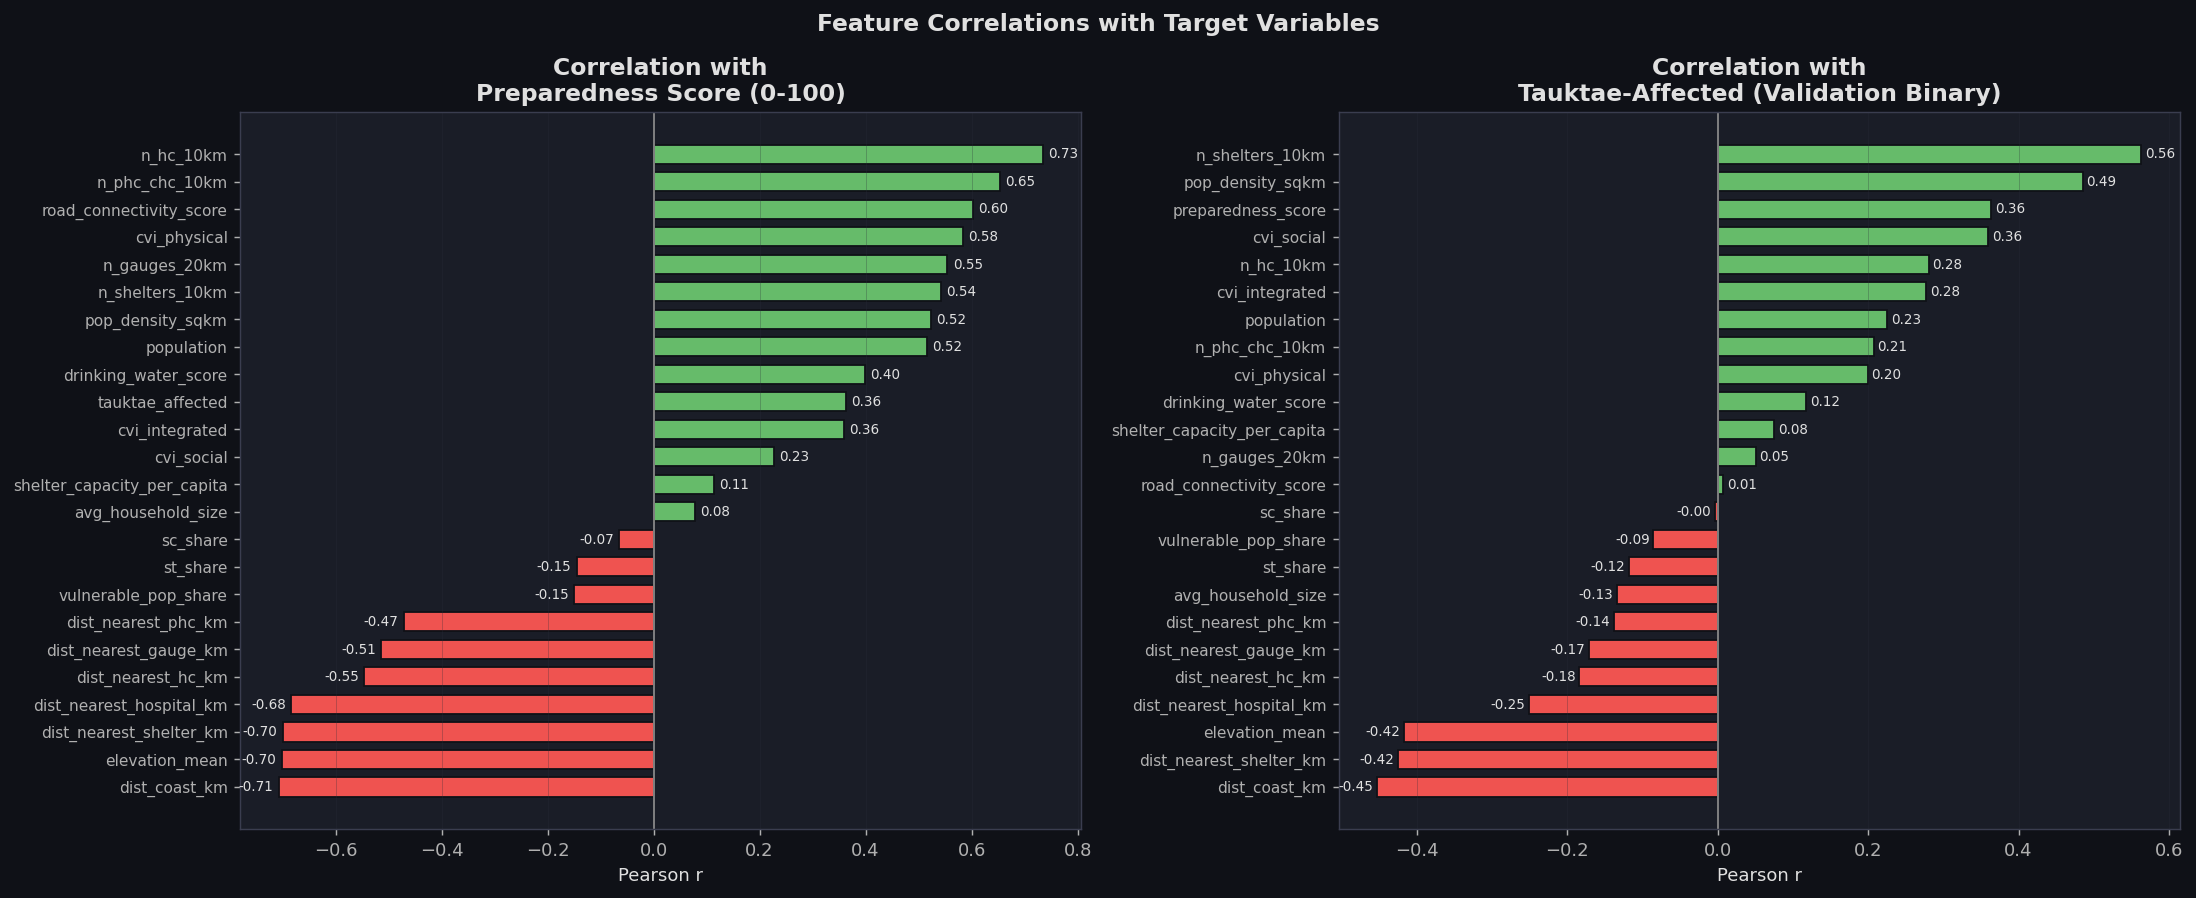

In [6]:
# Targeted heatmap: correlation with the target (Preparedness Score)
target_corr = numeric_df.corr()["preparedness_score"].drop("preparedness_score").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
fig.suptitle("Feature Correlations with Target Variables", fontsize=13, fontweight="bold")

# Left: with preparedness_score
colors_left = ["#EF5350" if v < 0 else "#66BB6A" for v in target_corr.values]
bars = axes[0].barh(range(len(target_corr)), target_corr.values, color=colors_left, edgecolor="#0f1117", height=0.7)
axes[0].set_yticks(range(len(target_corr)))
axes[0].set_yticklabels(target_corr.index, fontsize=8.5)
axes[0].axvline(0, color="#888888", linewidth=1)
axes[0].set_xlabel("Pearson r", fontsize=10)
axes[0].set_title("Correlation with\nPreparedness Score (0-100)", fontweight="bold")
axes[0].grid(axis="x", alpha=0.3)
for bar, val in zip(bars, target_corr.values):
    axes[0].text(val + (0.01 if val >= 0 else -0.01), bar.get_y() + bar.get_height()/2,
                 f"{val:.2f}", va="center", ha="left" if val >= 0 else "right", fontsize=7.5, color="#e0e0e0")

# Right: with tauktae_affected
tauktae_corr = numeric_df.corr()["tauktae_affected"].drop("tauktae_affected").sort_values()
colors_right = ["#EF5350" if v < 0 else "#66BB6A" for v in tauktae_corr.values]
bars2 = axes[1].barh(range(len(tauktae_corr)), tauktae_corr.values, color=colors_right, edgecolor="#0f1117", height=0.7)
axes[1].set_yticks(range(len(tauktae_corr)))
axes[1].set_yticklabels(tauktae_corr.index, fontsize=8.5)
axes[1].axvline(0, color="#888888", linewidth=1)
axes[1].set_xlabel("Pearson r", fontsize=10)
axes[1].set_title("Correlation with\nTauktae-Affected (Validation Binary)", fontweight="bold")
axes[1].grid(axis="x", alpha=0.3)
for bar, val in zip(bars2, tauktae_corr.values):
    axes[1].text(val + (0.005 if val >= 0 else -0.005), bar.get_y() + bar.get_height()/2,
                 f"{val:.2f}", va="center", ha="left" if val >= 0 else "right", fontsize=7.5, color="#e0e0e0")

plt.tight_layout()
plt.savefig("../notebooks/fig_04_target_correlations.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 4. Bivariate Analysis -- Feature Interactions

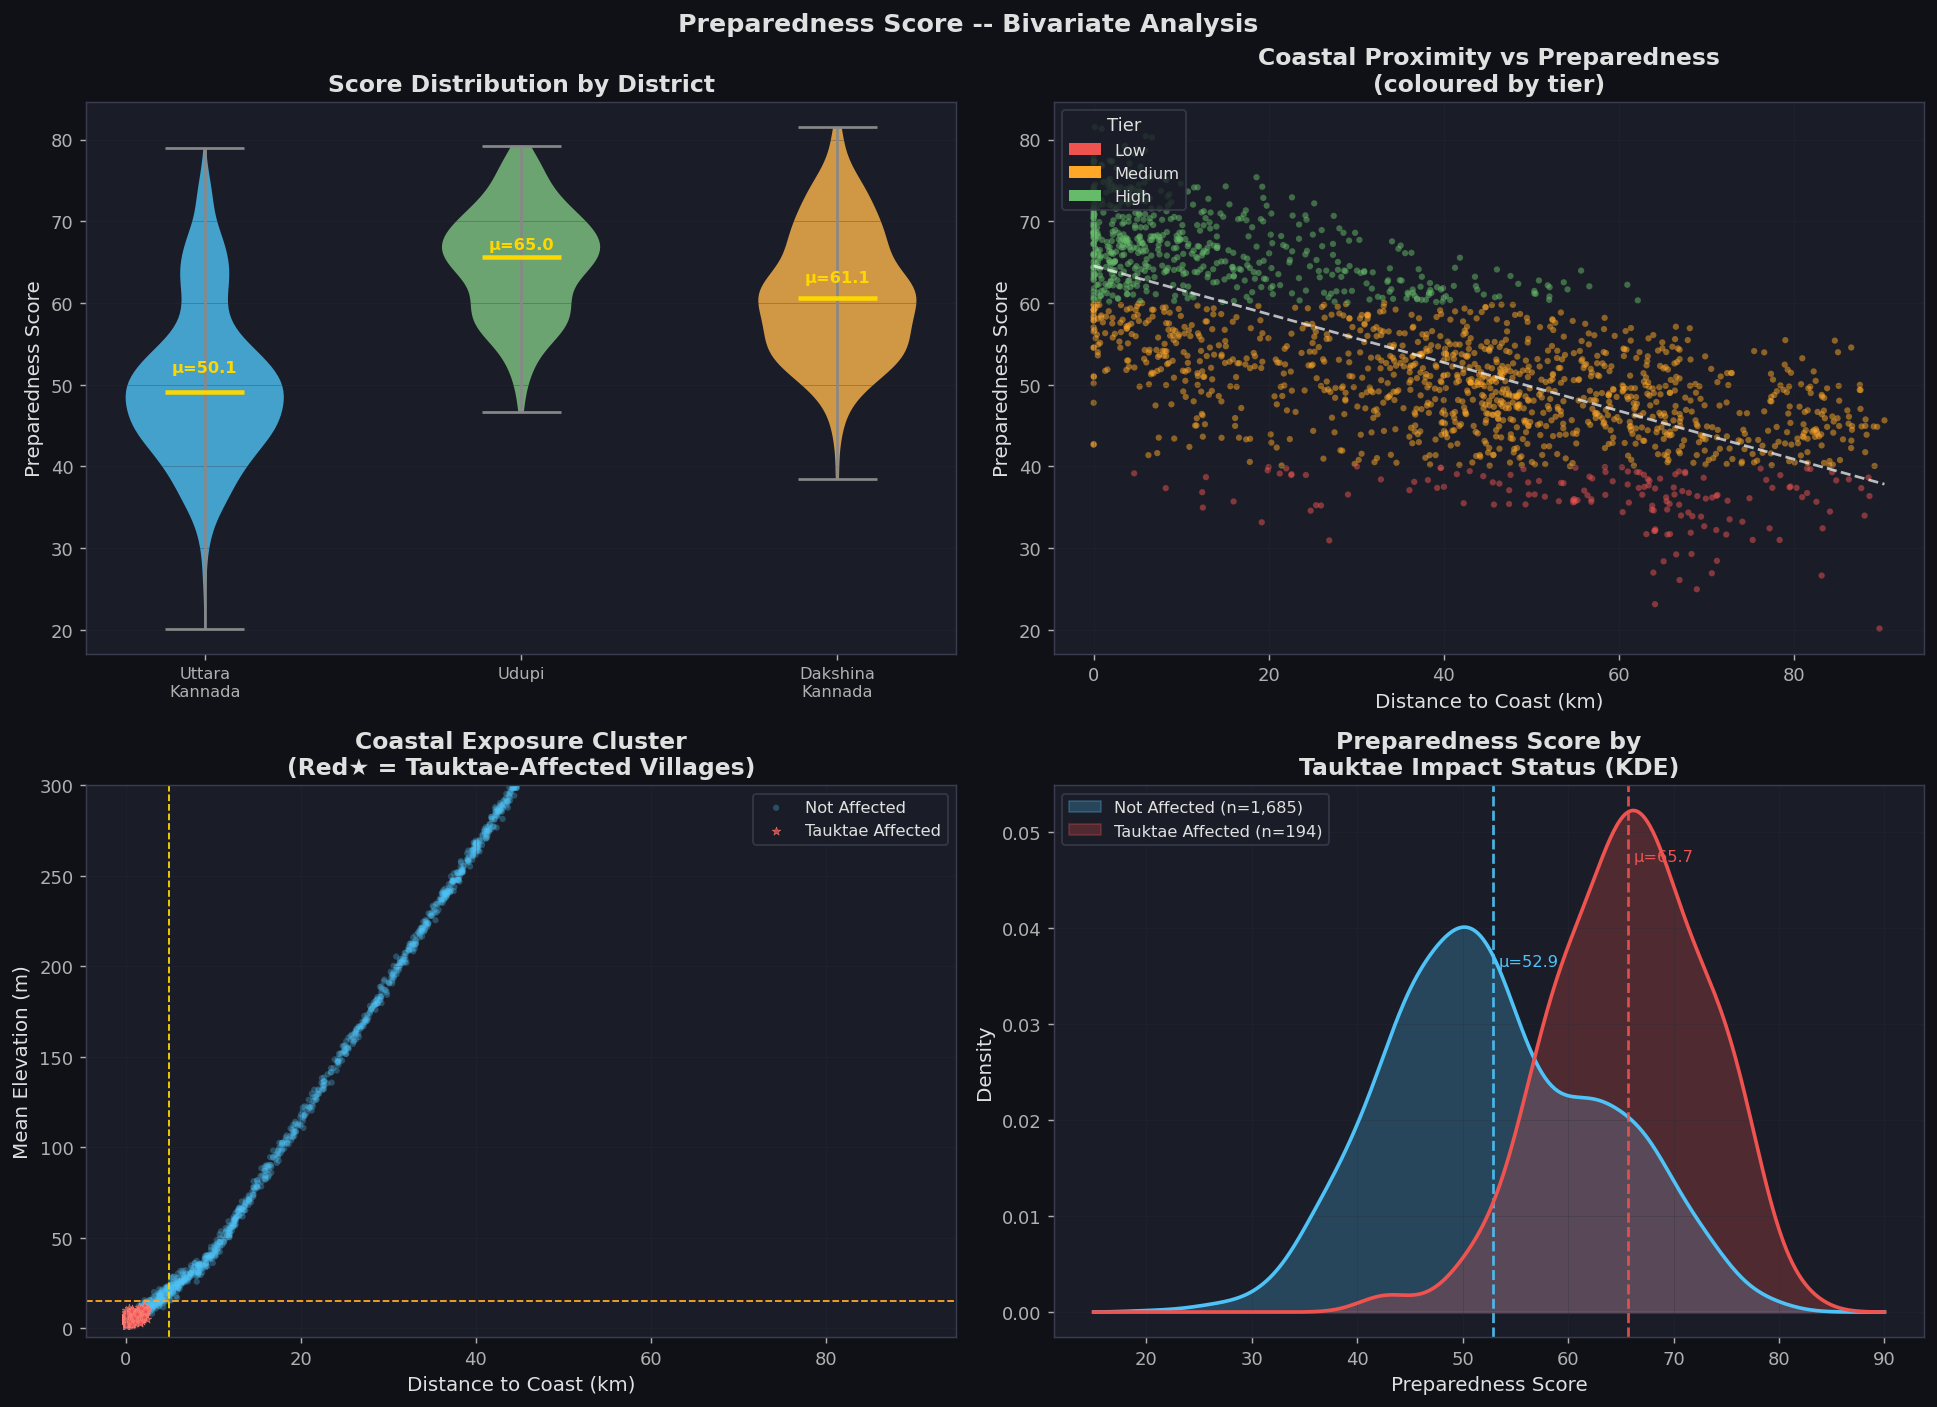

In [7]:
# Preparedness score distributions by district and tier
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("Preparedness Score -- Bivariate Analysis", fontsize=14, fontweight="bold")

# 1. Violin: Score by district
district_order = ["Uttara Kannada", "Udupi", "Dakshina Kannada"]
data_by_district = [df[df["district_name"] == d]["preparedness_score"].values for d in district_order]
parts = axes[0,0].violinplot(data_by_district, positions=[1,2,3], showmedians=True, showextrema=True)
for i, (body, color_key) in enumerate(zip(parts["bodies"], district_order)):
    body.set_facecolor(PALETTE_DISTRICT[color_key])
    body.set_alpha(0.8)
parts["cmedians"].set_color("#FFD700")
parts["cmedians"].set_linewidth(2.5)
parts["cmaxes"].set_color("#888888")
parts["cmins"].set_color("#888888")
parts["cbars"].set_color("#888888")
axes[0,0].set_xticks([1,2,3])
axes[0,0].set_xticklabels(["Uttara\nKannada","Udupi","Dakshina\nKannada"], fontsize=9)
axes[0,0].set_ylabel("Preparedness Score")
axes[0,0].set_title("Score Distribution by District", fontweight="bold")
axes[0,0].grid(axis="y", alpha=0.3)

# Add mean annotations
for i, (d, pos) in enumerate(zip(district_order, [1,2,3])):
    m = df[df["district_name"]==d]["preparedness_score"].mean()
    axes[0,0].text(pos, m+1.5, f"μ={m:.1f}", ha="center", fontsize=9, color="#FFD700", fontweight="bold")

# 2. Scatter: dist_coast_km vs preparedness_score (coloured by tier)
tier_map = {"Low":0, "Medium":1, "High":2}
c_vals = [TIER_COLORS[t] for t in df["preparedness_tier"].astype(str)]
sc = axes[0,1].scatter(df["dist_coast_km"], df["preparedness_score"],
                        c=c_vals, alpha=0.5, s=12, edgecolors="none")
axes[0,1].set_xlabel("Distance to Coast (km)")
axes[0,1].set_ylabel("Preparedness Score")
axes[0,1].set_title("Coastal Proximity vs Preparedness\n(coloured by tier)", fontweight="bold")
axes[0,1].grid(alpha=0.3)
legend_elems = [Patch(facecolor=TIER_COLORS[t], label=t) for t in ["Low","Medium","High"]]
axes[0,1].legend(handles=legend_elems, title="Tier", loc="upper left", fontsize=9)

# Add regression line
from numpy.polynomial import polynomial as P
x = df["dist_coast_km"].values
y = df["preparedness_score"].values
coeff = np.polyfit(x, y, 1)
x_line = np.linspace(0, x.max(), 200)
axes[0,1].plot(x_line, np.polyval(coeff, x_line), "w--", linewidth=1.5, alpha=0.7, label=f"OLS r={np.corrcoef(x,y)[0,1]:.2f}")

# 3. Scatter: elevation_mean vs dist_coast_km (tauktae overlay)
sc2 = axes[1,0].scatter(
    df[df["tauktae_affected"]==0]["dist_coast_km"],
    df[df["tauktae_affected"]==0]["elevation_mean"],
    c="#4FC3F7", alpha=0.3, s=12, label="Not Affected", edgecolors="none"
)
sc3 = axes[1,0].scatter(
    df[df["tauktae_affected"]==1]["dist_coast_km"],
    df[df["tauktae_affected"]==1]["elevation_mean"],
    c="#EF5350", alpha=0.8, s=25, label="Tauktae Affected", marker="*", edgecolors="#FF8A80", linewidth=0.3
)
axes[1,0].set_xlabel("Distance to Coast (km)")
axes[1,0].set_ylabel("Mean Elevation (m)")
axes[1,0].set_title("Coastal Exposure Cluster\n(Red★ = Tauktae-Affected Villages)", fontweight="bold")
axes[1,0].legend(fontsize=9)
axes[1,0].set_ylim(-5, 300)
axes[1,0].grid(alpha=0.3)
axes[1,0].axvline(5, color="#FFD700", linewidth=1, linestyle="--", label="5 km risk zone")
axes[1,0].axhline(15, color="#FFA726", linewidth=1, linestyle="--", label="15 m elev threshold")

# 4. KDE plot: Score by Tauktae outcome
from scipy.stats import gaussian_kde
for label, color, filter_val in [("Not Affected","#4FC3F7",0), ("Tauktae Affected","#EF5350",1)]:
    data = df[df["tauktae_affected"]==filter_val]["preparedness_score"].dropna()
    kde = gaussian_kde(data, bw_method="scott")
    x_r = np.linspace(15, 90, 500)
    axes[1,1].fill_between(x_r, kde(x_r), alpha=0.25, color=color, label=f"{label} (n={len(data):,})")
    axes[1,1].plot(x_r, kde(x_r), color=color, linewidth=2)
    axes[1,1].axvline(data.mean(), color=color, linewidth=1.5, linestyle="--", alpha=0.9)
    axes[1,1].text(data.mean()+0.5, kde(x_r).max()*0.9, f"μ={data.mean():.1f}", color=color, fontsize=9)
axes[1,1].set_xlabel("Preparedness Score")
axes[1,1].set_ylabel("Density")
axes[1,1].set_title("Preparedness Score by\nTauktae Impact Status (KDE)", fontweight="bold")
axes[1,1].legend(fontsize=9)
axes[1,1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_05_bivariate.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 5. Geographic Scatter Maps

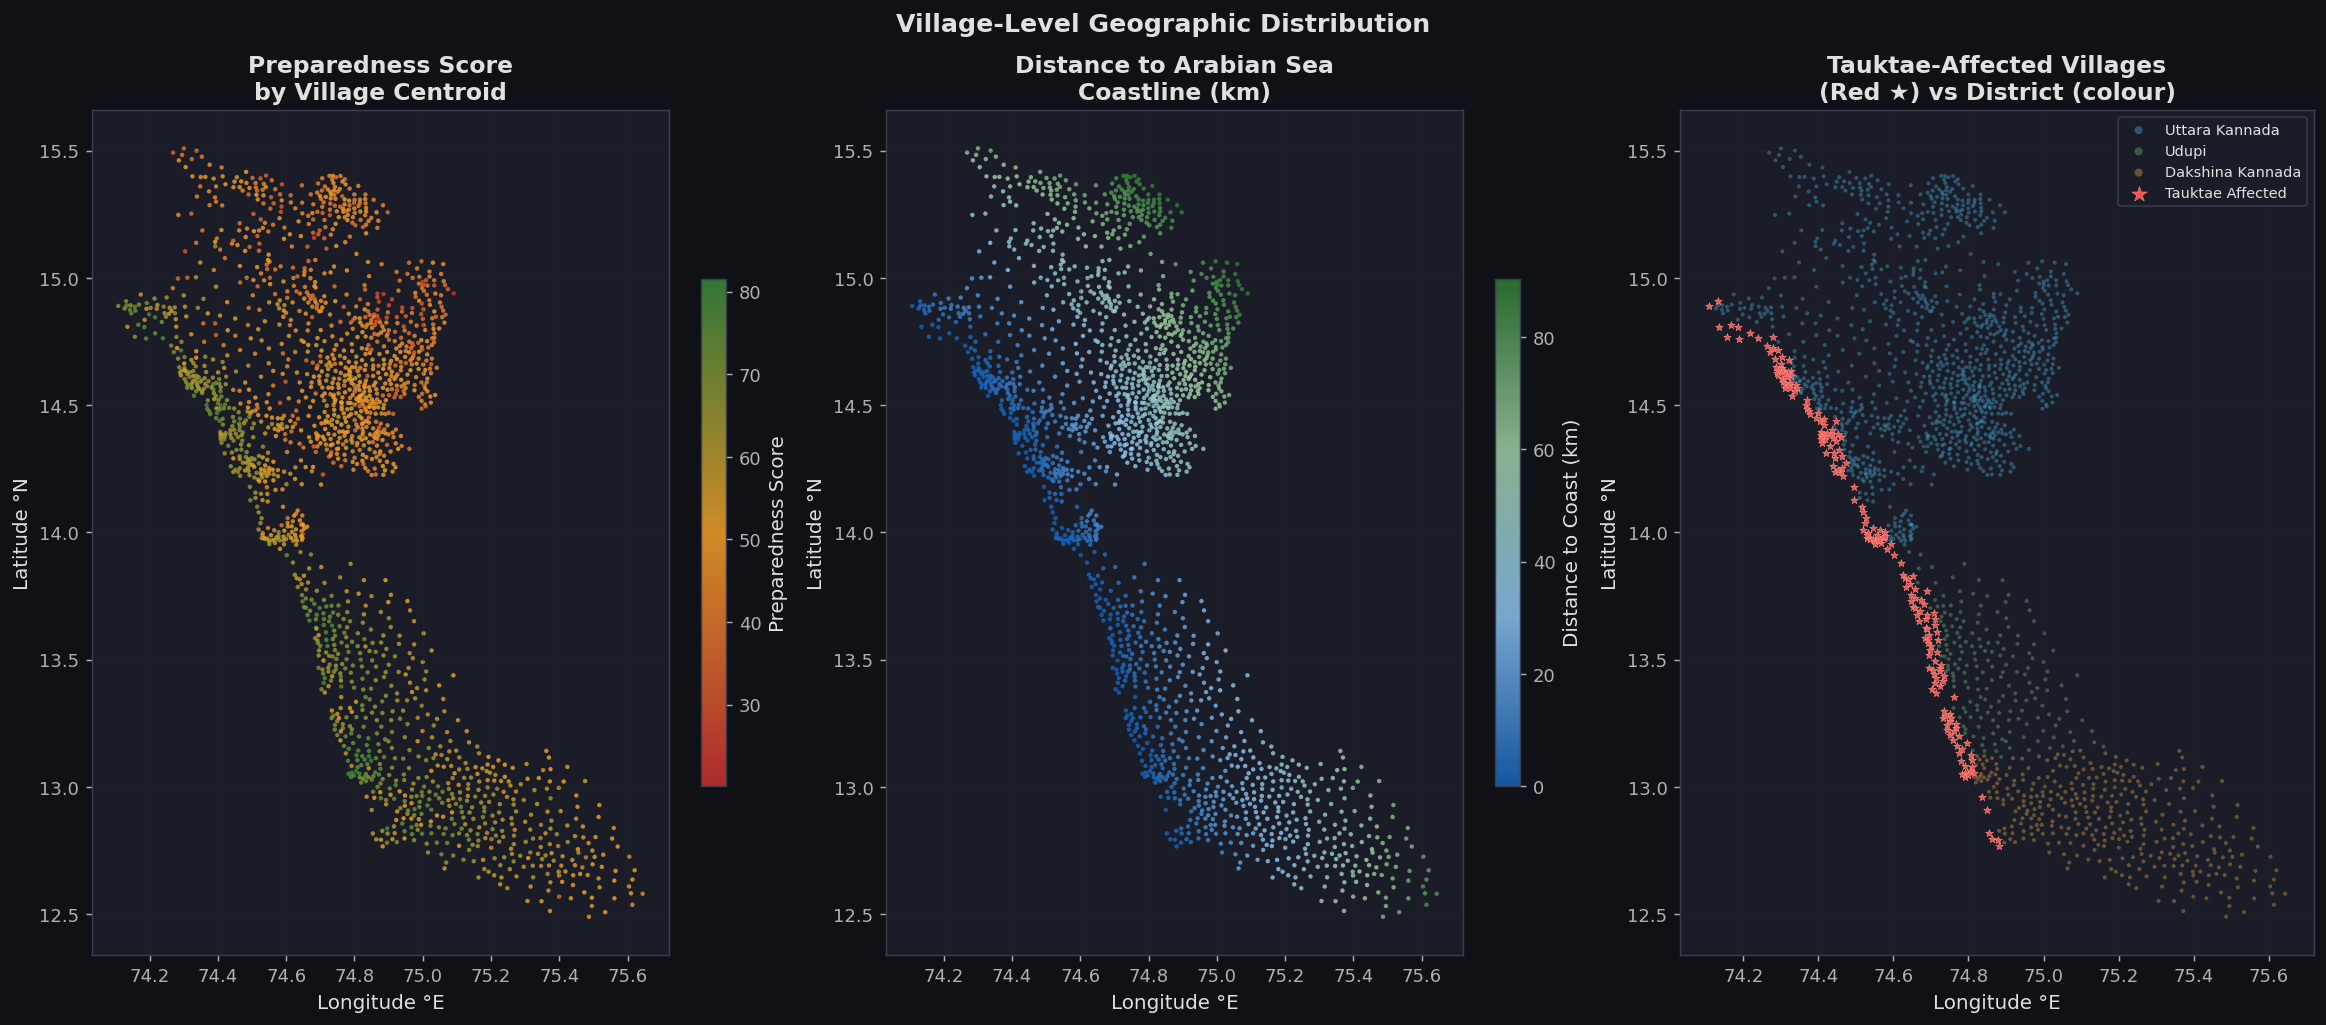

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
fig.suptitle("Village-Level Geographic Distribution", fontsize=14, fontweight="bold")

cmap_score = LinearSegmentedColormap.from_list("score", ["#D32F2F","#FFA726","#388E3C"], N=256)

# Map 1: Preparedness Score
sc1 = axes[0].scatter(df["lon"], df["lat"], c=df["preparedness_score"],
                       cmap=cmap_score, s=6, alpha=0.8, edgecolors="none")
plt.colorbar(sc1, ax=axes[0], label="Preparedness Score", fraction=0.04)
axes[0].set_title("Preparedness Score\nby Village Centroid", fontweight="bold")
axes[0].set_xlabel("Longitude °E"); axes[0].set_ylabel("Latitude °N")
axes[0].grid(alpha=0.25)

# Map 2: Distance to Coast
cmap_coast = LinearSegmentedColormap.from_list("coast",["#1565C0","#90CAF9","#A5D6A7","#2E7D32"])
sc2 = axes[1].scatter(df["lon"], df["lat"], c=df["dist_coast_km"],
                       cmap=cmap_coast, s=6, alpha=0.8, edgecolors="none")
plt.colorbar(sc2, ax=axes[1], label="Distance to Coast (km)", fraction=0.04)
axes[1].set_title("Distance to Arabian Sea\nCoastline (km)", fontweight="bold")
axes[1].set_xlabel("Longitude °E"); axes[1].set_ylabel("Latitude °N")
axes[1].grid(alpha=0.25)

# Map 3: Tauktae affected + district overlay
for dist, color in PALETTE_DISTRICT.items():
    sub = df[df["district_name"]==dist]
    axes[2].scatter(sub["lon"], sub["lat"], c=color, s=5, alpha=0.35, edgecolors="none", label=dist)
# Overlay tauktae affected
taf = df[df["tauktae_affected"]==1]
axes[2].scatter(taf["lon"], taf["lat"], c="#EF5350", s=20, alpha=1.0,
                marker="*", edgecolors="#FF8A80", linewidth=0.3, zorder=5, label="Tauktae Affected")
axes[2].set_title("Tauktae-Affected Villages\n(Red ★) vs District (colour)", fontweight="bold")
axes[2].set_xlabel("Longitude °E"); axes[2].set_ylabel("Latitude °N")
axes[2].legend(fontsize=8, markerscale=2)
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.savefig("../notebooks/fig_06_geographic.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 6. Weight Justification -- Analytic Hierarchy Process (AHP)

The composite Preparedness Score uses a **weighted linear combination** of five normalised sub-scores.  
Weights were derived using **Saaty's Analytic Hierarchy Process (AHP)**, cross-referenced against the NDMA framework and the Sendai DRR literature.

$$\text{Preparedness Score} = 0.25 S_{\text{medical}} + 0.25 S_{\text{shelters}} + 0.20 S_{\text{infra}} + 0.15 S_{\text{ew}} + 0.15 S_{\text{socio}}$$

The pairwise comparison scale (Saaty 1-9) rates which dimension is *more important* for immediate cyclone survival in the 0-72 hour window.


Principal eigenvalue (lambda_max): 5.00060
Consistency Index (CI):            0.00015
Consistency Ratio (CR):            0.00013  ✅ Consistent (CR < 0.10)

Derived AHP Weights:
  Medical
Access           : 0.2501  (25.0%)
  Shelters &
Evacuation    : 0.2501  (25.0%)
  Road &
Infra             : 0.1998  (20.0%)
  Early
  Socio-
Economic          : 0.1500  (15.0%)


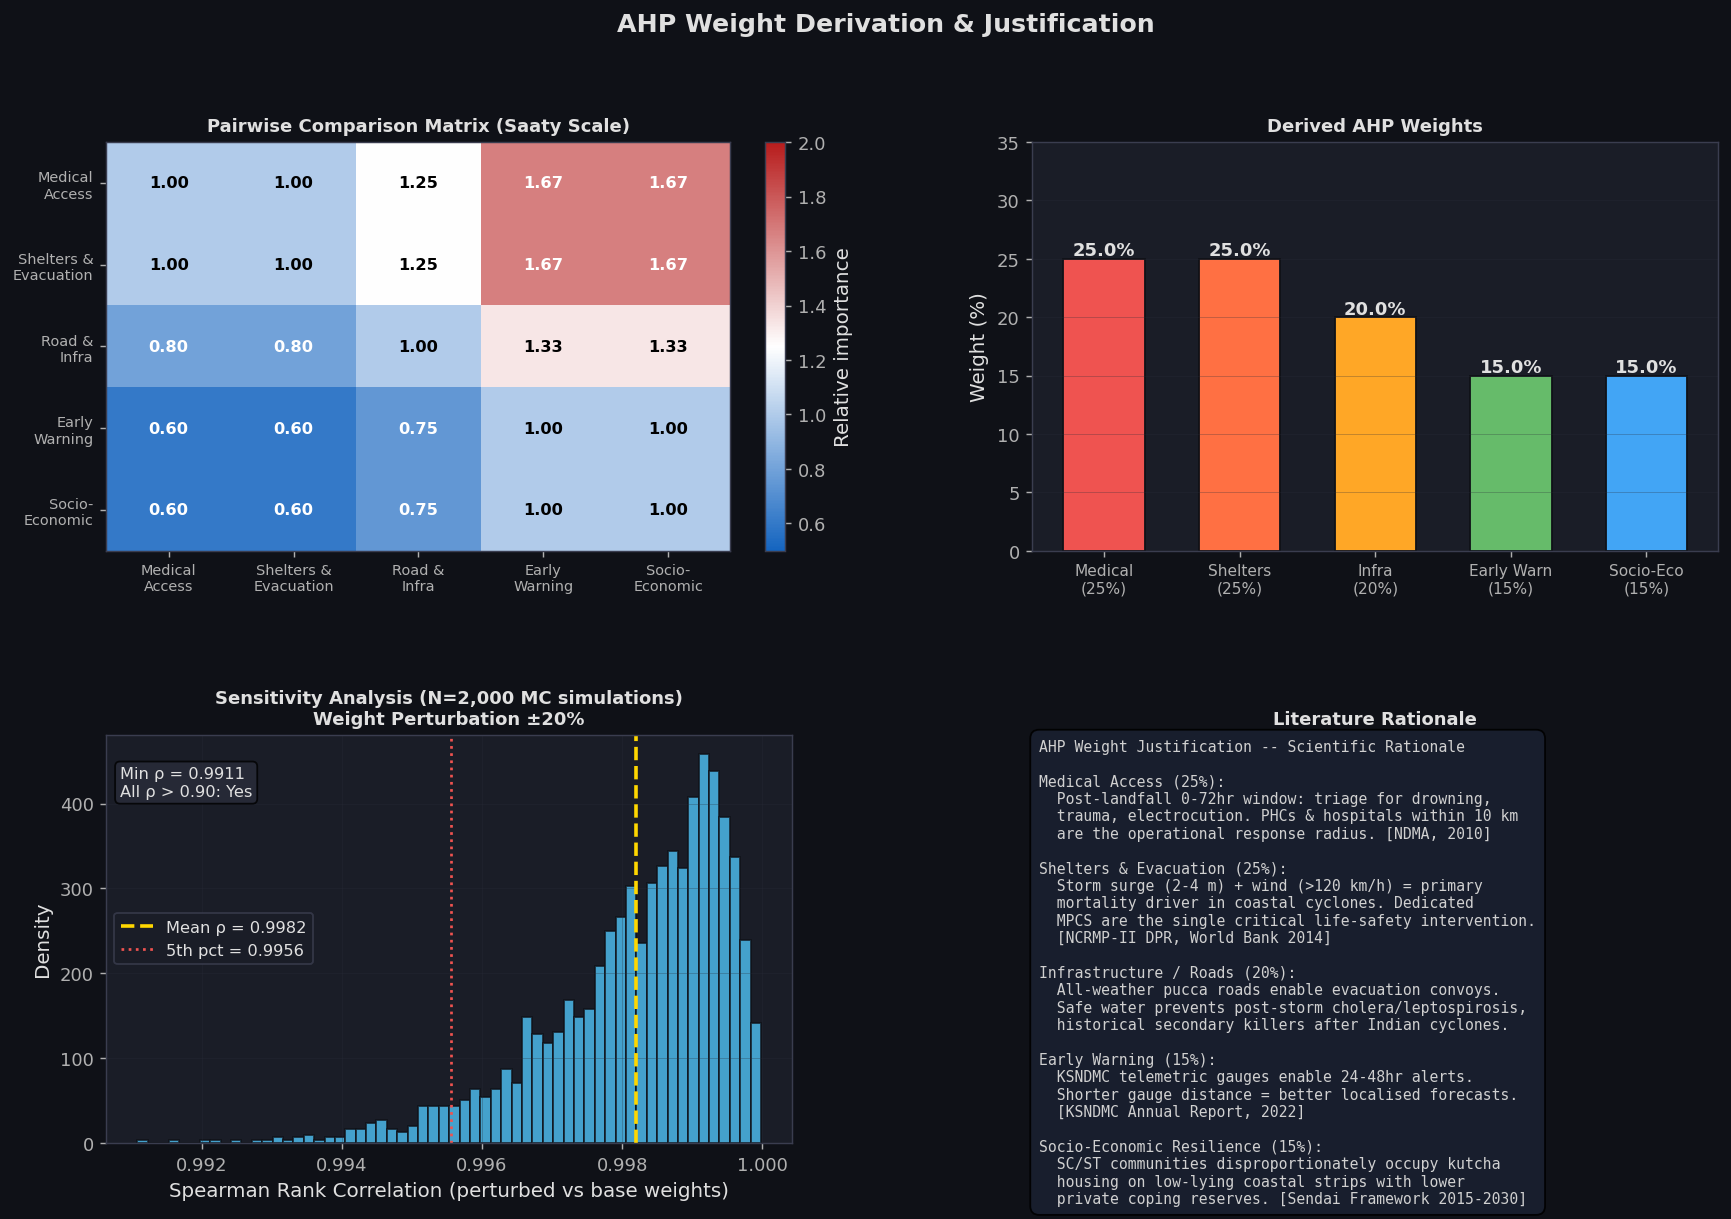


Consistency Ratio: 0.0001 -- Weights are mathematically consistent.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# AHP pairwise matrix (Saaty 1-9 scale)
dims = ["Medical\nAccess", "Shelters &\nEvacuation", "Road &\nInfra", "Early\nWarning", "Socio-\nEconomic"]
A = np.array([
    [1.00, 1.00, 1.25, 1.67, 1.67],
    [1.00, 1.00, 1.25, 1.67, 1.67],
    [0.80, 0.80, 1.00, 1.33, 1.33],
    [0.60, 0.60, 0.75, 1.00, 1.00],
    [0.60, 0.60, 0.75, 1.00, 1.00],
])

# Compute AHP weights from principal eigenvector
eigenvalues, eigenvectors = np.linalg.eig(A)
max_idx = np.argmax(eigenvalues.real)
w_raw = eigenvectors[:, max_idx].real
w_raw = np.abs(w_raw)
w = w_raw / w_raw.sum()
lam_max = eigenvalues[max_idx].real
CI = (lam_max - len(dims)) / (len(dims) - 1)
RI = 1.12  # Random index for n=5
CR = CI / RI

print(f"Principal eigenvalue (lambda_max): {lam_max:.5f}")
print(f"Consistency Index (CI):            {CI:.5f}")
print(f"Consistency Ratio (CR):            {CR:.5f}  {'✅ Consistent (CR < 0.10)' if CR < 0.10 else '❌ Inconsistent'}")
print(f"\nDerived AHP Weights:")
for d, wi in zip(dims, w):
    print(f"  {d:25s}: {wi:.4f}  ({wi*100:.1f}%)")

fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle("AHP Weight Derivation & Justification", fontsize=14, fontweight="bold")

# Plot 1: Pairwise comparison matrix heatmap
ax1 = fig.add_subplot(gs[0, 0])
cmap_ahp = LinearSegmentedColormap.from_list("ahp", ["#1565C0","#FFFFFF","#B71C1C"])
im = ax1.imshow(A, cmap=cmap_ahp, aspect="auto", vmin=0.5, vmax=2.0)
for i in range(5):
    for j in range(5):
        ax1.text(j, i, f"{A[i,j]:.2f}", ha="center", va="center",
                 fontsize=9, color="black" if 0.8 < A[i,j] < 1.5 else "white", fontweight="bold")
ax1.set_xticks(range(5)); ax1.set_yticks(range(5))
ax1.set_xticklabels(dims, fontsize=8); ax1.set_yticklabels(dims, fontsize=8)
ax1.set_title("Pairwise Comparison Matrix (Saaty Scale)", fontweight="bold", fontsize=10)
plt.colorbar(im, ax=ax1, label="Relative importance", fraction=0.04)

# Plot 2: Derived weights bar chart
ax2 = fig.add_subplot(gs[0, 1])
colours_ahp = ["#EF5350","#FF7043","#FFA726","#66BB6A","#42A5F5"]
bar_labels   = ["Medical\n(25%)", "Shelters\n(25%)", "Infra\n(20%)", "Early Warn\n(15%)", "Socio-Eco\n(15%)"]
bars2 = ax2.bar(range(5), w * 100, color=colours_ahp, edgecolor="#0f1117", width=0.6)
for bar, wi in zip(bars2, w):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f"{wi*100:.1f}%", ha="center", fontsize=10, color="#e0e0e0", fontweight="bold")
ax2.set_xticks(range(5)); ax2.set_xticklabels(bar_labels, fontsize=8.5)
ax2.set_ylabel("Weight (%)")
ax2.set_title("Derived AHP Weights", fontweight="bold", fontsize=10)
ax2.set_ylim(0, 35)
ax2.grid(axis="y", alpha=0.3)

# Plot 3: Sensitivity analysis -- Monte Carlo weight perturbation
np.random.seed(42)
N_MC = 2000
perturbations = np.random.uniform(0.8, 1.2, size=(N_MC, 5))
mc_weights = (perturbations * w) / (perturbations * w).sum(axis=1, keepdims=True)

from scipy.stats import spearmanr
BASE_SCORE_DIMS = ["score_medical","score_shelters","score_infrastructure","score_early_warning","score_socioeconomic"]
base_score = sum(w[i] * df[BASE_SCORE_DIMS[i]] for i in range(5))

rho_values = []
for mc_w in mc_weights:
    mc_score = sum(mc_w[i] * df[BASE_SCORE_DIMS[i]] for i in range(5))
    rho, _ = spearmanr(base_score, mc_score)
    rho_values.append(rho)

ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(rho_values, bins=60, color="#4FC3F7", edgecolor="#0f1117", alpha=0.8, density=True)
ax3.axvline(np.mean(rho_values), color="#FFD700", linewidth=2, linestyle="--",
            label=f"Mean ρ = {np.mean(rho_values):.4f}")
ax3.axvline(np.percentile(rho_values, 5), color="#EF5350", linewidth=1.5, linestyle=":",
            label=f"5th pct = {np.percentile(rho_values, 5):.4f}")
ax3.set_xlabel("Spearman Rank Correlation (perturbed vs base weights)")
ax3.set_ylabel("Density")
ax3.set_title(f"Sensitivity Analysis (N={N_MC:,} MC simulations)\nWeight Perturbation ±20%", fontweight="bold", fontsize=10)
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)
ax3.text(0.02, 0.85, f"Min ρ = {min(rho_values):.4f}\nAll ρ > 0.90: {'Yes' if min(rho_values)>0.90 else 'No'}",
         transform=ax3.transAxes, fontsize=9, color="#e0e0e0",
         bbox=dict(boxstyle="round", facecolor="#2a2d3a", alpha=0.8))

# Plot 4: Literature / framework rationale
ax4 = fig.add_subplot(gs[1, 1])
ax4.axis("off")
justification_text = "\n".join([
    "AHP Weight Justification -- Scientific Rationale", "",
    "Medical Access (25%):",
    "  Post-landfall 0-72hr window: triage for drowning,",
    "  trauma, electrocution. PHCs & hospitals within 10 km",
    "  are the operational response radius. [NDMA, 2010]", "",
    "Shelters & Evacuation (25%):",
    "  Storm surge (2-4 m) + wind (>120 km/h) = primary",
    "  mortality driver in coastal cyclones. Dedicated",
    "  MPCS are the single critical life-safety intervention.",
    "  [NCRMP-II DPR, World Bank 2014]", "",
    "Infrastructure / Roads (20%):",
    "  All-weather pucca roads enable evacuation convoys.",
    "  Safe water prevents post-storm cholera/leptospirosis,",
    "  historical secondary killers after Indian cyclones.", "",
    "Early Warning (15%):",
    "  KSNDMC telemetric gauges enable 24-48hr alerts.",
    "  Shorter gauge distance = better localised forecasts.",
    "  [KSNDMC Annual Report, 2022]", "",
    "Socio-Economic Resilience (15%):",
    "  SC/ST communities disproportionately occupy kutcha",
    "  housing on low-lying coastal strips with lower",
    "  private coping reserves. [Sendai Framework 2015-2030]"
])
ax4.text(0.01, 0.99, justification_text, transform=ax4.transAxes,
         fontsize=8.2, va="top", color="#d0d0d0",
         fontfamily="monospace",
         bbox=dict(boxstyle="round", facecolor="#1a2030", alpha=0.9, pad=0.6))
ax4.set_title("Literature Rationale", fontweight="bold", fontsize=10)

plt.savefig("../notebooks/fig_07_ahp_weights.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()
print(f"\nConsistency Ratio: {CR:.4f} -- {'Weights are mathematically consistent.' if CR<0.10 else 'Review pairwise matrix.'}")


## 7. Feature Engineering

In [10]:
from sklearn.preprocessing import RobustScaler, PowerTransformer, LabelEncoder
from scipy.stats import boxcox

df_fe = df.copy()

# === FE-1: Log Transforms for highly skewed distance/count features ===
SKEWED_FEATURES = [
    "population", "pop_density_sqkm",
    "dist_nearest_hospital_km", "dist_nearest_shelter_km",
    "shelter_capacity_nearby", "shelter_capacity_per_capita",
]

print("=" * 60)
print("FE-1: Log1p Transform (reduce right skew)")
print("=" * 60)
for feat in SKEWED_FEATURES:
    orig_skew = skew(df_fe[feat].dropna())
    df_fe[f"log1p_{feat}"] = np.log1p(df_fe[feat].clip(0))
    new_skew = skew(df_fe[f"log1p_{feat}"].dropna())
    print(f"  {feat:40s}: {orig_skew:+.2f} → {new_skew:+.2f}")

# === FE-2: Coastal Risk Proximity Score ===
df_fe["coastal_risk_score"] = (
    np.exp(-df_fe["dist_coast_km"] / 10.0) *       # Exponential decay with coast distance
    np.exp(-df_fe["elevation_mean"] / 30.0)          # Exponential decay with elevation
).round(4)
print("\nFE-2: Coastal Risk Proximity Score (exp decay by coast dist + elevation)")
print(f"  Range: {df_fe['coastal_risk_score'].min():.4f} - {df_fe['coastal_risk_score'].max():.4f}")

# === FE-3: Healthcare Access Gap ===
# A village with many gauges but far from a hospital has a SPLIT in coverage
df_fe["healthcare_access_gap"] = (
    (df_fe["dist_nearest_hospital_km"] / 100.0) -
    (df_fe["n_hc_10km"] / df_fe["n_hc_10km"].max())
).round(4)
print("\nFE-3: Healthcare Access Gap (hospital distance vs local facility density)")

# === FE-4: Evacuation Capacity Ratio ===
pop_safe = df_fe["population"].replace(0, np.nan)
df_fe["evacuation_sufficiency"] = (
    df_fe["shelter_capacity_nearby"] / pop_safe.fillna(1)
).clip(0, 10).round(4)
print("FE-4: Evacuation Sufficiency Ratio (shelter capacity / village population)")

# === FE-5: Composite Vulnerability Exposure ===
df_fe["vulnerability_exposure"] = (
    0.5 * (df_fe["cvi_integrated"] / df_fe["cvi_integrated"].max()) +
    0.3 * (1 - df_fe["dist_coast_km"] / df_fe["dist_coast_km"].max()) +
    0.2 * df_fe["vulnerable_pop_share"]
).round(4)
print("FE-5: Composite Vulnerability Exposure (CVI + coastal proximity + demography)")

# === FE-6: Infrastructure Composite ===
df_fe["infra_composite"] = (
    df_fe["road_connectivity_score"] / 3.0 +
    df_fe["drinking_water_score"] / 2.0 +
    df_fe["bus_connectivity"].astype(float)
).round(4) / 3.0
print("FE-6: Infrastructure Composite (road + water + bus)")

# === FE-7: Monitoring Coverage ===
df_fe["monitoring_coverage"] = (
    (1 - df_fe["dist_nearest_gauge_km"] / df_fe["dist_nearest_gauge_km"].max()) * 0.6 +
    (df_fe["n_gauges_20km"] / df_fe["n_gauges_20km"].max()) * 0.4
).round(4)
print("FE-7: Monitoring Coverage Score (gauge proximity + density)")

print("\nNew engineered features added:", [c for c in df_fe.columns if c not in df.columns])


FE-1: Log1p Transform (reduce right skew)
  population                              : +2.76 → -1.42
  pop_density_sqkm                        : +4.05 → -1.06
  dist_nearest_hospital_km                : -0.32 → -1.50
  dist_nearest_shelter_km                 : +0.29 → -0.91
  shelter_capacity_nearby                 : +2.35 → +1.67
  shelter_capacity_per_capita             : +17.85 → +5.18

FE-2: Coastal Risk Proximity Score (exp decay by coast dist + elevation)
  Range: 0.0000 - 0.9512

FE-3: Healthcare Access Gap (hospital distance vs local facility density)
FE-4: Evacuation Sufficiency Ratio (shelter capacity / village population)
FE-5: Composite Vulnerability Exposure (CVI + coastal proximity + demography)
FE-6: Infrastructure Composite (road + water + bus)
FE-7: Monitoring Coverage Score (gauge proximity + density)

New engineered features added: ['log1p_population', 'log1p_pop_density_sqkm', 'log1p_dist_nearest_hospital_km', 'log1p_dist_nearest_shelter_km', 'log1p_shelter_capacity_

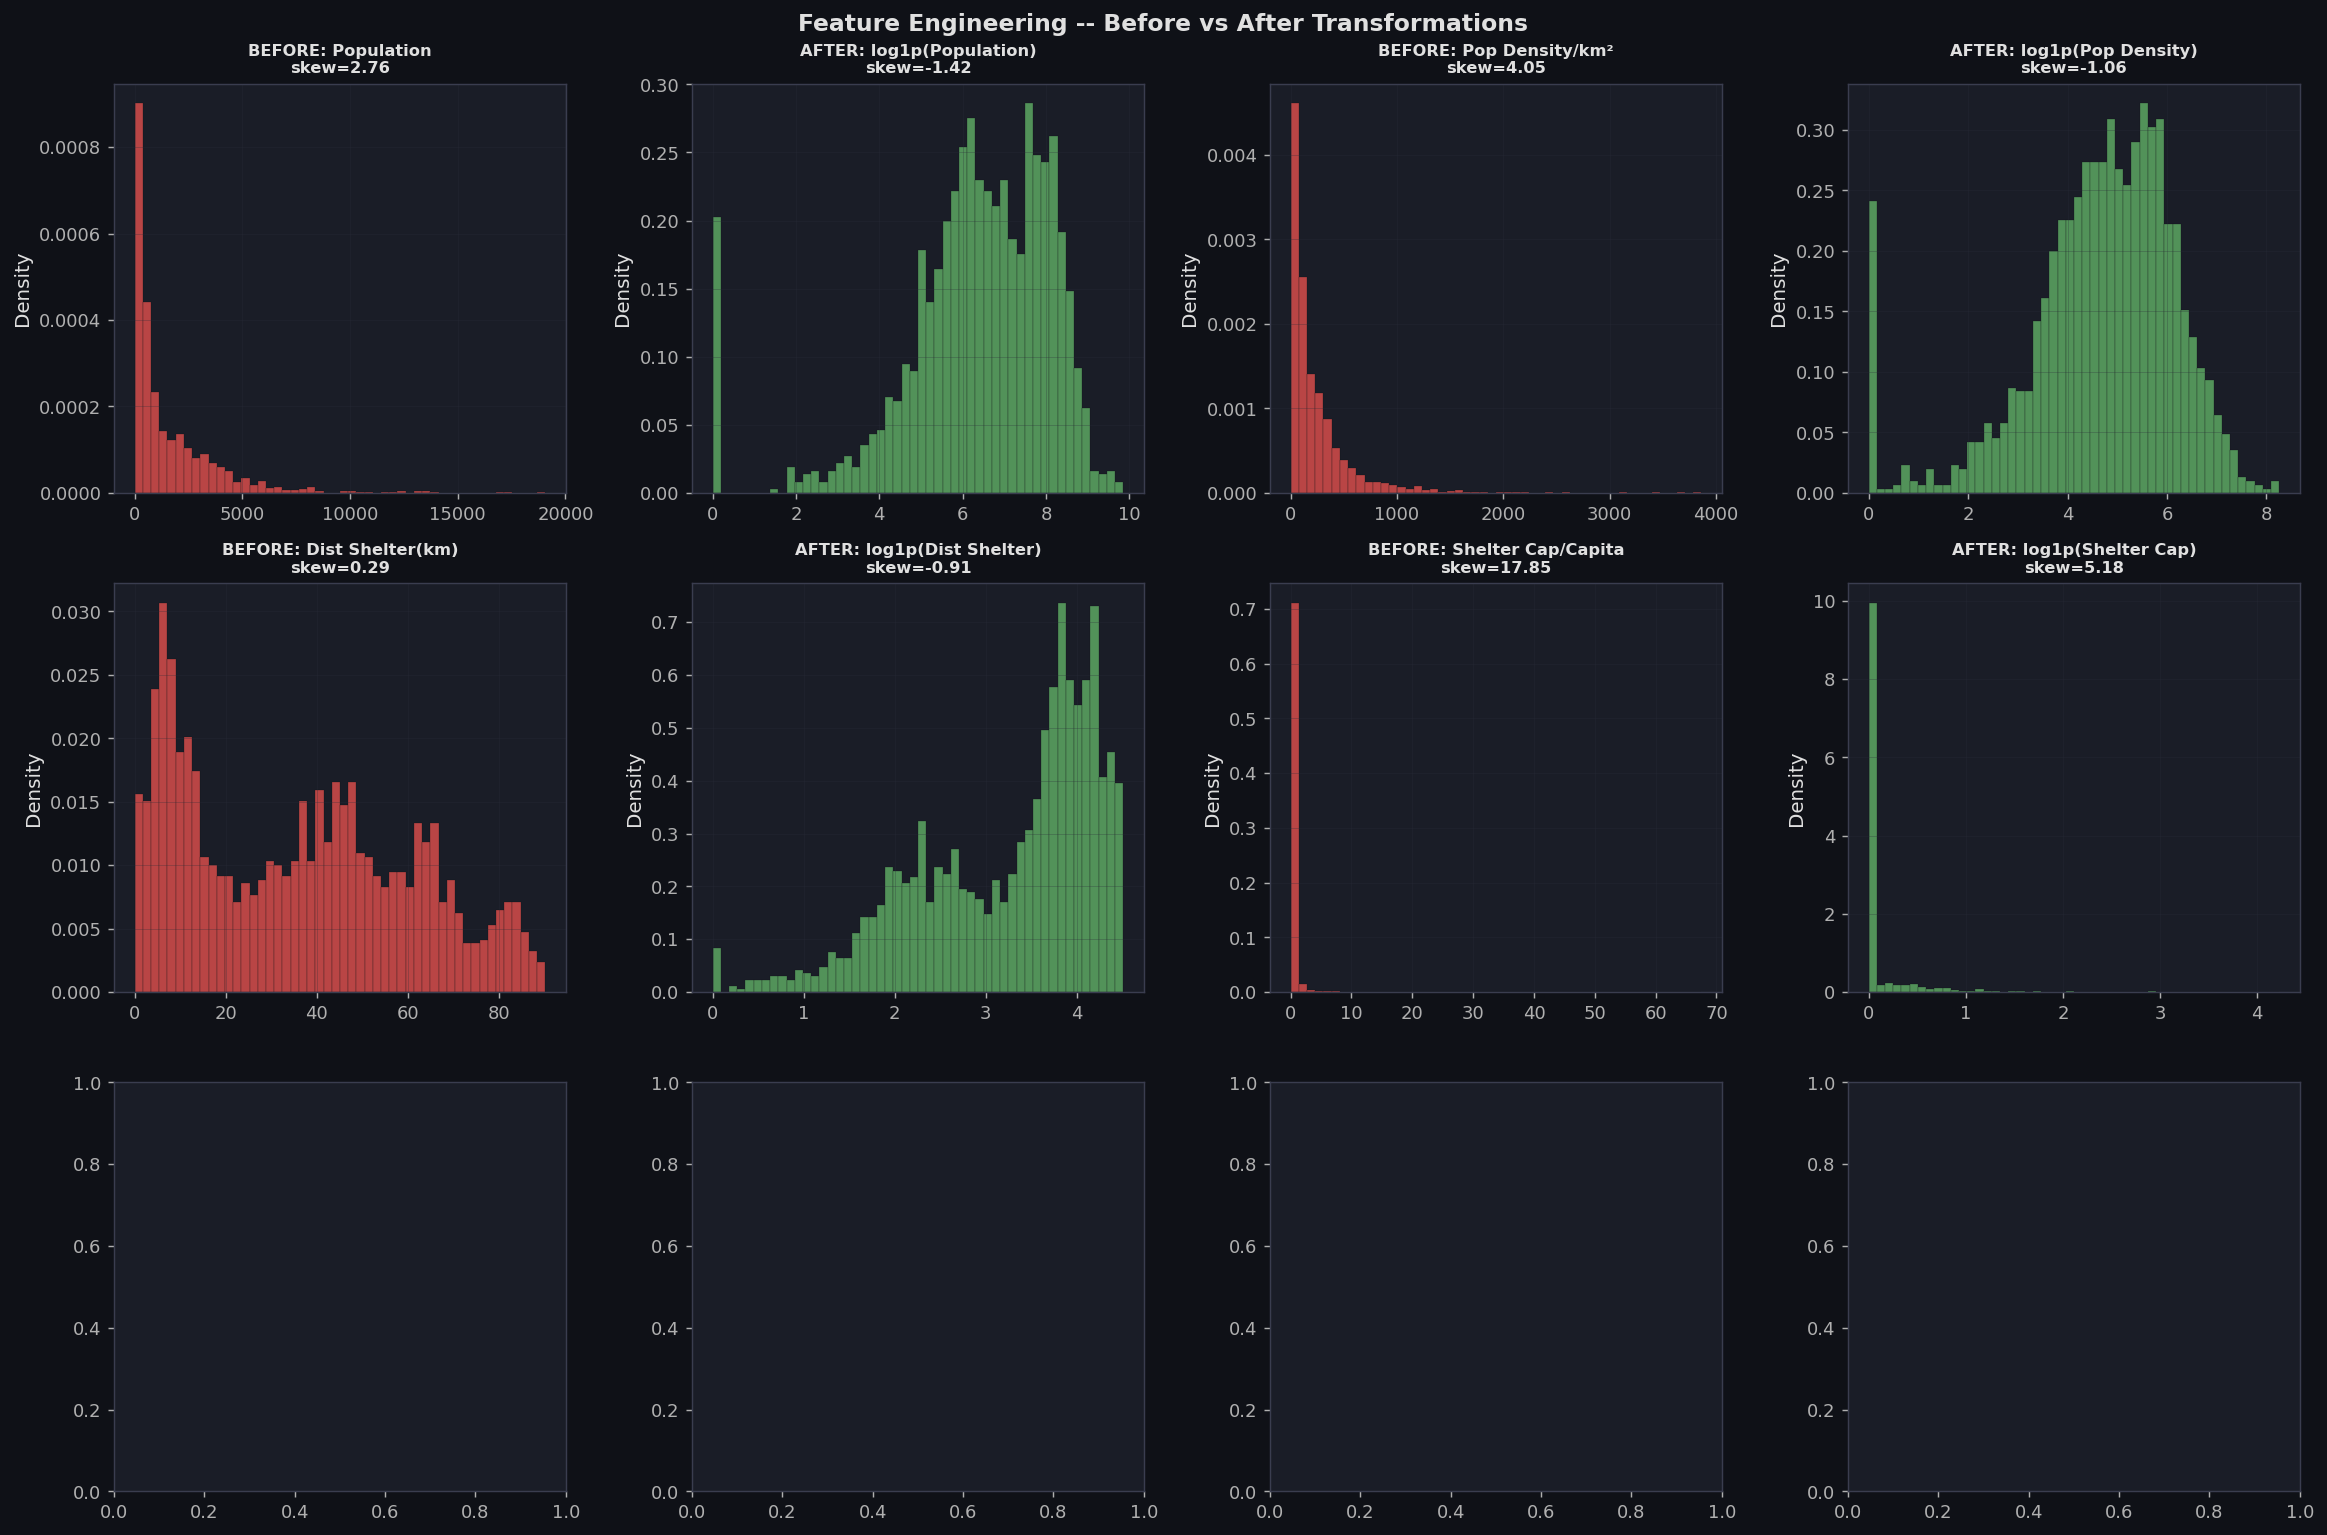

In [11]:
# Visualise transformations (before vs after)
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
fig.suptitle("Feature Engineering -- Before vs After Transformations", fontsize=13, fontweight="bold")

pairs = [
    ("population",             "log1p_population",          "Population",          "log1p(Population)"),
    ("pop_density_sqkm",       "log1p_pop_density_sqkm",    "Pop Density/km²",     "log1p(Pop Density)"),
    ("dist_nearest_shelter_km","log1p_dist_nearest_shelter_km","Dist Shelter(km)","log1p(Dist Shelter)"),
    ("shelter_capacity_per_capita","log1p_shelter_capacity_per_capita","Shelter Cap/Capita","log1p(Shelter Cap)"),
]

colors_before = "#EF5350"
colors_after  = "#66BB6A"

for i, (orig, trans, lab_orig, lab_trans) in enumerate(pairs):
    ax_b = axes[i*2]
    ax_a = axes[i*2 + 1]
    
    data_orig = df_fe[orig].dropna()
    data_trans = df_fe[trans].dropna()
    
    ax_b.hist(data_orig, bins=50, color=colors_before, alpha=0.75, density=True, edgecolor="#0f1117", linewidth=0.2)
    ax_b.set_title(f"BEFORE: {lab_orig}\nskew={skew(data_orig):.2f}", fontsize=9, fontweight="bold")
    ax_b.set_ylabel("Density"); ax_b.grid(alpha=0.3)
    
    ax_a.hist(data_trans, bins=50, color=colors_after, alpha=0.75, density=True, edgecolor="#0f1117", linewidth=0.2)
    ax_a.set_title(f"AFTER: {lab_trans}\nskew={skew(data_trans):.2f}", fontsize=9, fontweight="bold")
    ax_a.set_ylabel("Density"); ax_a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_08_fe_transforms.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


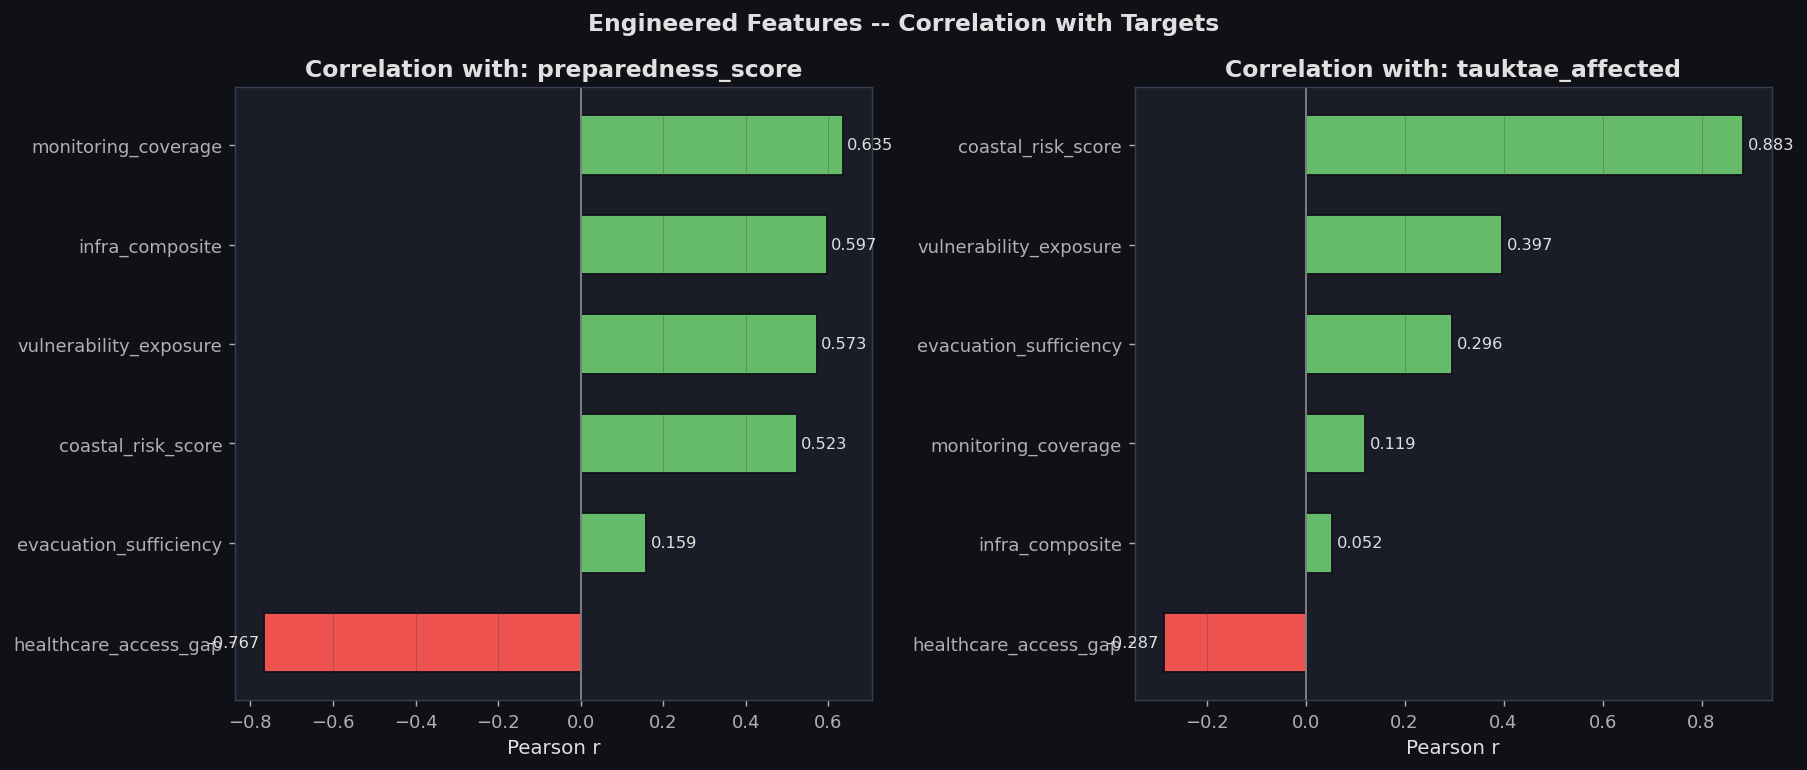

In [12]:
# Engineered feature correlation with targets
new_feats = ["coastal_risk_score","healthcare_access_gap","evacuation_sufficiency",
             "vulnerability_exposure","infra_composite","monitoring_coverage"]
fe_corr = df_fe[new_feats + ["preparedness_score","tauktae_affected"]].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Engineered Features -- Correlation with Targets", fontsize=13, fontweight="bold")

for ax, target in zip(axes, ["preparedness_score", "tauktae_affected"]):
    feat_corrs = fe_corr[target][new_feats].sort_values()
    colors = ["#EF5350" if v < 0 else "#66BB6A" for v in feat_corrs.values]
    ax.barh(range(len(feat_corrs)), feat_corrs.values, color=colors, edgecolor="#0f1117", height=0.6)
    ax.set_yticks(range(len(feat_corrs)))
    ax.set_yticklabels(feat_corrs.index, fontsize=10)
    ax.axvline(0, color="#888", linewidth=1)
    for i, (idx, val) in enumerate(feat_corrs.items()):
        ax.text(val + (0.01 if val >= 0 else -0.01), i, f"{val:.3f}",
                va="center", ha="left" if val >= 0 else "right", fontsize=9)
    ax.set_title(f"Correlation with: {target}", fontweight="bold")
    ax.set_xlabel("Pearson r")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("../notebooks/fig_09_fe_correlations.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()


## 8. Preprocessing Pipeline

dist_coast_km             | Raw: μ=34.85, σ=25.65 → Scaled: μ=-0.013, σ=0.566
elevation_mean            | Raw: μ=232.88, σ=185.01 → Scaled: μ=0.000, σ=0.548


n_hc_10km                 | Raw: μ=21.93, σ=15.61 → Scaled: μ=0.283, σ=0.744


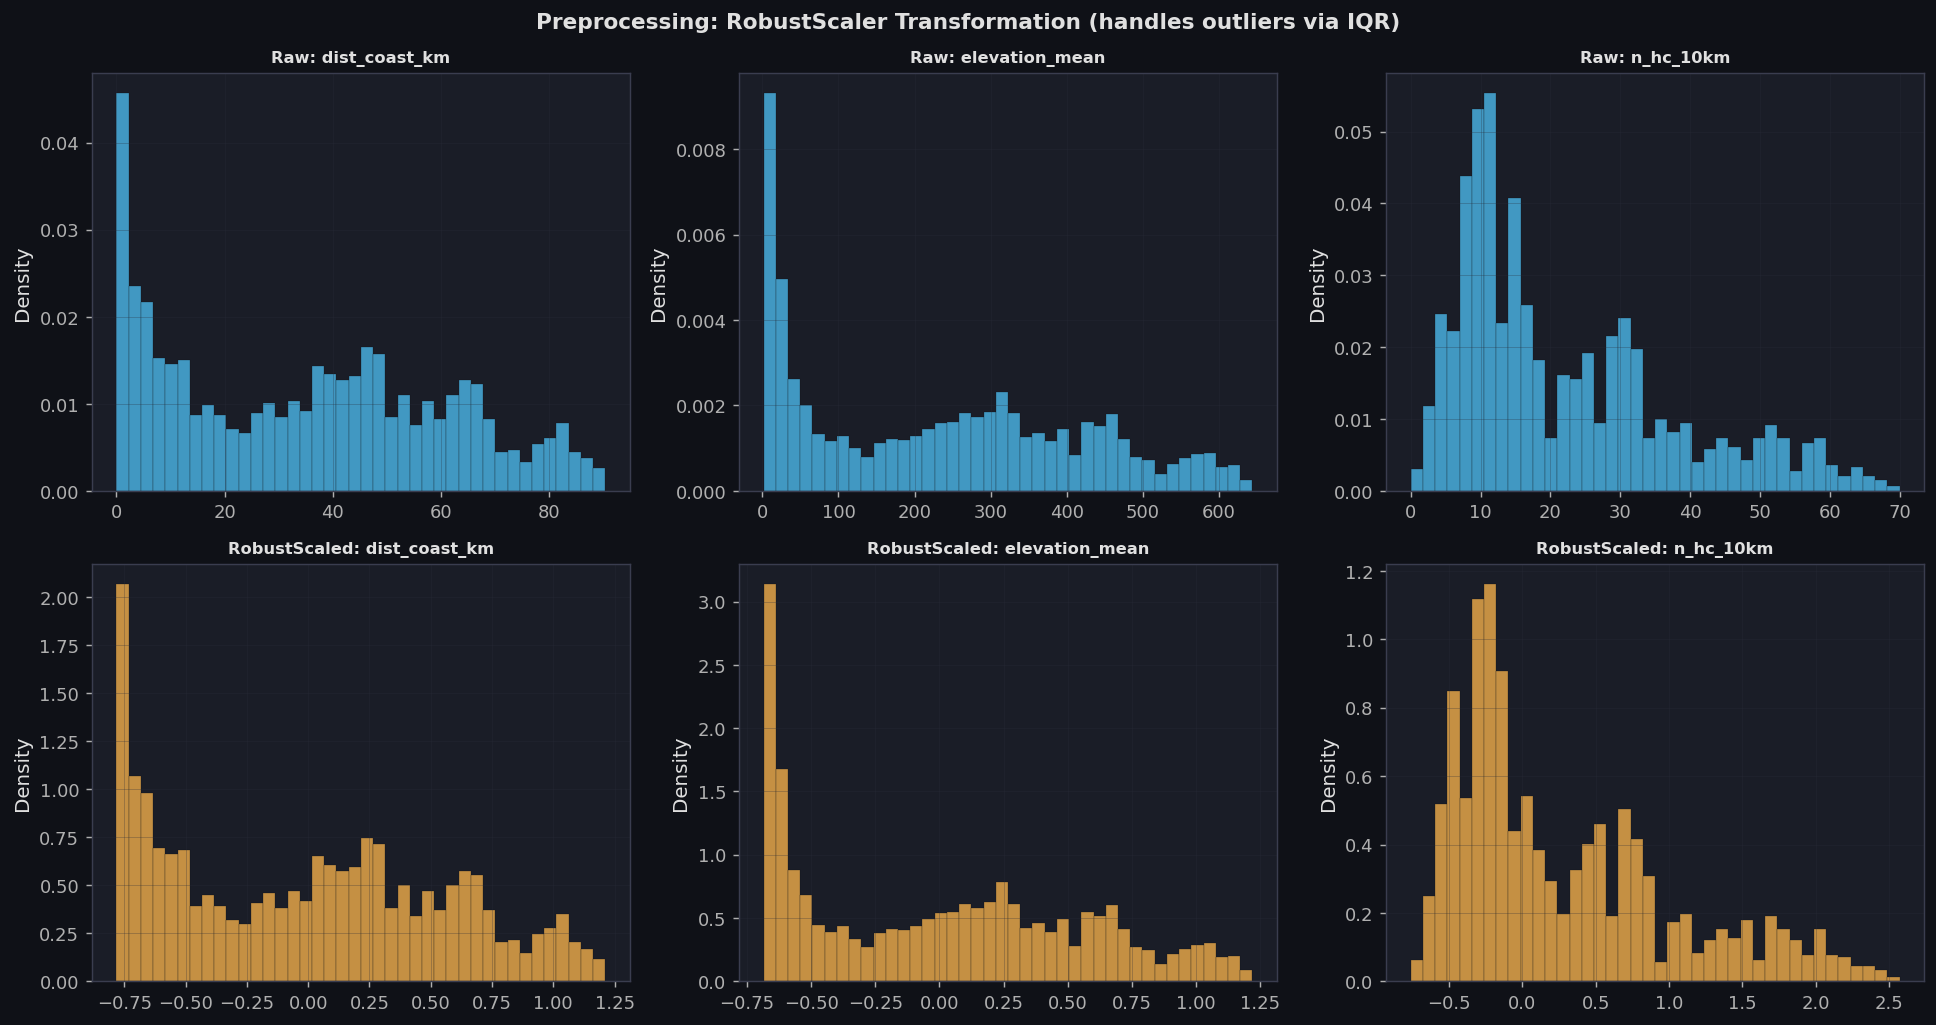


Saved modelling dataset: 1,879 rows × 33 features
Features: 26 | Target(reg): preparedness_score | Target(cls): preparedness_tier


In [13]:
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Feature sets for modelling
MODEL_FEATURES = [
    # Core numeric (raw)
    "dist_coast_km", "elevation_mean", "avg_household_size",
    "sc_share", "st_share", "vulnerable_pop_share",
    "road_connectivity_score", "drinking_water_score",
    "n_hc_10km", "n_phc_chc_10km",
    "n_gauges_20km", "n_shelters_10km",
    "cvi_physical", "cvi_social",
    "has_pucca_road", "has_major_district_road", "bus_connectivity",
    # Engineered
    "log1p_population", "log1p_pop_density_sqkm",
    "log1p_dist_nearest_shelter_km", "log1p_dist_nearest_hospital_km",
    "coastal_risk_score", "evacuation_sufficiency",
    "vulnerability_exposure", "infra_composite", "monitoring_coverage",
]

TARGET_REGRESSION     = "preparedness_score"
TARGET_CLASSIFICATION = "preparedness_tier"

# Show RobustScaler effect on key features
scaler = RobustScaler()
robust_scaled = pd.DataFrame(
    scaler.fit_transform(df_fe[["dist_coast_km","elevation_mean","n_hc_10km"]]),
    columns=["dist_coast_km", "elevation_mean", "n_hc_10km"]
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Preprocessing: RobustScaler Transformation (handles outliers via IQR)", fontsize=12, fontweight="bold")

for i, feat in enumerate(["dist_coast_km","elevation_mean","n_hc_10km"]):
    # Raw
    axes[0, i].hist(df_fe[feat].dropna(), bins=40, color="#4FC3F7", density=True, alpha=0.75, edgecolor="#0f1117", linewidth=0.2)
    axes[0, i].set_title(f"Raw: {feat}", fontsize=9, fontweight="bold")
    axes[0, i].set_ylabel("Density"); axes[0, i].grid(alpha=0.3)
    
    # Scaled
    axes[1, i].hist(robust_scaled[feat], bins=40, color="#FFB74D", density=True, alpha=0.75, edgecolor="#0f1117", linewidth=0.2)
    axes[1, i].set_title(f"RobustScaled: {feat}", fontsize=9, fontweight="bold")
    axes[1, i].set_ylabel("Density"); axes[1, i].grid(alpha=0.3)
    
    print(f"{feat:25s} | Raw: μ={df_fe[feat].mean():.2f}, σ={df_fe[feat].std():.2f} → Scaled: μ={robust_scaled[feat].mean():.3f}, σ={robust_scaled[feat].std():.3f}")

plt.tight_layout()
plt.savefig("../notebooks/fig_10_preprocessing.png", dpi=130, bbox_inches="tight", facecolor="#0f1117")
plt.show()

# Save final modelling dataset
df_model = df_fe[["area_id","village_code","village_name","district_name"] + MODEL_FEATURES + [TARGET_REGRESSION, TARGET_CLASSIFICATION, "tauktae_affected"]].copy()
df_model.to_parquet("../data/processed/modelling_dataset.parquet", index=False)
print(f"\nSaved modelling dataset: {df_model.shape[0]:,} rows × {df_model.shape[1]} features")
print(f"Features: {len(MODEL_FEATURES)} | Target(reg): {TARGET_REGRESSION} | Target(cls): {TARGET_CLASSIFICATION}")
